# Delta Air Lines: Flight Delay Prediction

**Applied Machine Learning - Fall 2026**

**Business question:** How can Delta Air Lines use historical flight information to anticipate arrival delays and support proactive operational decision-making?

**Machine learning question:** Using only information available before scheduled departure, how accurately can we predict whether a Delta-operated flight will arrive at least 15 minutes late, and which pre-departure flight characteristics are most predictive of delay risk?

**Scope:** U.S. BTS Reporting Carrier On-Time Performance records for 2025. We predict `ARR_DEL15` for completed flights with observed arrival outcomes. 

**Prediction timing:** Before scheduled departure. Actual departure/arrival outcomes must never be predictors.

This notebook shows every step from raw data to models: loading the data (Section 2), checking its quality (Section 3), cleaning it and making features (Section 4), and preparing it for the models (Section 5). All findings are based on the output shown below.


#LAD OS KIGGE PÅ DENNE START IGEN INDEN VI AFLEVERER, HVIS DER SKAL TILFØJES NOGET ELLER MANGLER NOGET

## 1. Import libraries and set the file paths

We load the Python libraries we need and point to the 12 monthly data files. The notebook must be run from the folder where both this notebook and the `data/` folder are placed. If a file is missing, the cell stops with an error that names the missing file.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
MONTHLY_FILES = [DATA_DIR / f"{month:02d}-2025.csv" for month in range(1, 13)]

missing_files = [str(path) for path in MONTHLY_FILES if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing BTS monthly file(s): {missing_files}")

print(f"Found all {len(MONTHLY_FILES)} monthly files.")

Found all 12 monthly files.


## 2. Data collection

We downloaded the 2025 flight data from the U.S. Bureau of Transportation Statistics (BTS) as 12 monthly files and stacked them into one table. To keep the data small, we only read the 11 columns we need from each file, and we only keep flights operated by Delta (DL). For each month we print the total number of flights and the number of Delta flights, so it is clear how the dataset was built. At the end, we check that all 12 months are there.

This is described in Section 2.1 of the report.

In [6]:
# the 11 columns we need, grouped in 4 categories
EXPECTED_COLUMNS = [
    # Flight Information
    "FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST",
    # Schedule
    "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE",
    # Flight Status
    "CANCELLED", "DIVERTED",
    # Outcome (target)
    "ARR_DEL15",
]

# an empty list where we save the Delta flights from each month
monthly_delta = []

# going through the 12 monthly files one by one
for file_path in MONTHLY_FILES:
    # reading only the 11 columns we need
    monthly = pd.read_csv(file_path, usecols=EXPECTED_COLUMNS)

    # keeping only flights operated by Delta (DL)
    delta = monthly[monthly["OP_UNIQUE_CARRIER"] == "DL"]

    # showing how many flights the file had, and how many were Delta
    print(file_path.name, "- all flights:", len(monthly), "- Delta flights:", len(delta))

    # saving the Delta flights in the list
    monthly_delta.append(delta)

# stacking the 12 months on top of each other into one table
df = pd.concat(monthly_delta, ignore_index=True)

# turn FL_DATE from text into a real date, so we can get the month and weekday later
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], format="%m/%d/%Y %I:%M:%S %p")

# show the total number of Delta flights in 2025
print("Total Delta flights in 2025:", len(df))

# check that we have flights from all 12 months (1 = January, 12 = December)
df["FL_DATE"].dt.month.value_counts().sort_index()

01-2025.csv - all flights: 539747 - Delta flights: 76306
02-2025.csv - all flights: 504884 - Delta flights: 71333
03-2025.csv - all flights: 600872 - Delta flights: 84487
04-2025.csv - all flights: 583950 - Delta flights: 84188
05-2025.csv - all flights: 605648 - Delta flights: 89931
06-2025.csv - all flights: 611575 - Delta flights: 91122
07-2025.csv - all flights: 631428 - Delta flights: 94066
08-2025.csv - all flights: 602378 - Delta flights: 90313
09-2025.csv - all flights: 562439 - Delta flights: 84875
10-2025.csv - all flights: 605844 - Delta flights: 90097
11-2025.csv - all flights: 570550 - Delta flights: 84475
12-2025.csv - all flights: 582304 - Delta flights: 85139
Total Delta flights in 2025: 1026332


FL_DATE
1     76306
2     71333
3     84487
4     84188
5     89931
6     91122
7     94066
8     90313
9     84875
10    90097
11    84475
12    85139
Name: count, dtype: int64

## 3. Getting to know the data (EDA) and data quality

**The main idea (from Session 2):** before we clean the data, we first look for problems. In this section we only **look** at the data. We do not change anything yet.

**The plan:**
1. Step 1 – How big is the data, and what type of data is in each column?
2. Step 2 (Check 1) – Does each column look normal on its own?
3. Step 3 (Check 2) – Do the columns make sense together?
4. Step 4 (Check 3) – Does the data follow the rules?
5. Step 5 (Check 4) – What is missing, and why?
6. Summary – the 7 data quality dimensions

**Step 1: How big is the data, and what type of data is in each column?**

In [7]:
# ===== EDA: size and data types =====
# show the first 5 rows, to check that the data was read in correctly
display(df.head(5))

# number of rows (flights) and columns
print("--- Size ---")
print("Rows (flights):", df.shape[0])
print("Columns:", df.shape[1])

# first and last date, number of different dates and airports
print("\n--- Dates and airports ---")
print("Date range:", df["FL_DATE"].min().date(), "to", df["FL_DATE"].max().date())
print("Unique dates:", df["FL_DATE"].nunique())
print("Unique origin airports:", df["ORIGIN"].nunique())
print("Unique destination airports:", df["DEST"].nunique())

# column names, how many cells are filled in, and the data type of each column
print("\n--- Data types ---")
df.info()

,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025-01-01,DL,ABQ,ATL,635,1132,0.0,0.0,0.0,177.0,1269.0
1,2025-01-01,DL,ABQ,ATL,1135,1633,0.0,0.0,0.0,178.0,1269.0
2,2025-01-01,DL,ABQ,MSP,800,1139,0.0,0.0,0.0,159.0,981.0
3,2025-01-01,DL,ALB,ATL,605,859,0.0,0.0,0.0,174.0,853.0
4,2025-01-01,DL,ALB,ATL,1413,1705,0.0,0.0,0.0,172.0,853.0


--- Size ---
Rows (flights): 1026332
Columns: 11

--- Dates and airports ---
Date range: 2025-01-01 to 2025-12-31
Unique dates: 365
Unique origin airports: 153
Unique destination airports: 153

--- Data types ---
<class 'pandas.DataFrame'>
RangeIndex: 1026332 entries, 0 to 1026331
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   FL_DATE            1026332 non-null  datetime64[us]
 1   OP_UNIQUE_CARRIER  1026332 non-null  str           
 2   ORIGIN             1026332 non-null  str           
 3   DEST               1026332 non-null  str           
 4   CRS_DEP_TIME       1026332 non-null  int64         
 5   CRS_ARR_TIME       1026332 non-null  int64         
 6   ARR_DEL15          1012427 non-null  float64       
 7   CANCELLED          1026332 non-null  float64       
 8   DIVERTED           1026332 non-null  float64       
 9   CRS_ELAPSED_TIME   1026332 non-null  float64       
 

**Findings – Step 1:**
- We have 1,026,332 Delta flights and 11 columns.
- All 365 days of 2025 are in the data.
- Delta flies from 153 airports and to 153 airports.
- The data types look right: FL_DATE is a date, ORIGIN, DEST and OP_UNIQUE_CARRIER are text, and the rest are numbers.
- Only ARR_DEL15 (the target) has empty cells. We look at this in Check 4.

**Step 2 (Check 1): Does each column look normal on its own? (Univariate analysis)**

,DISTANCE,CRS_ELAPSED_TIME
count,1026332.0,1026332.0
mean,959.0,161.0
std,653.0,80.0
min,95.0,44.0
25%,481.0,101.0
50%,761.0,139.0
75%,1276.0,202.0
max,5095.0,739.0


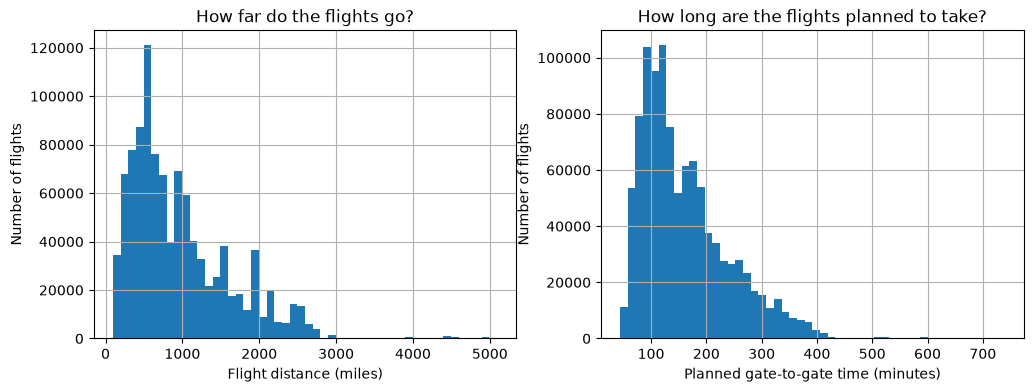

ARR_DEL15
0.0    0.802
1.0    0.198
Name: proportion, dtype: float64


In [8]:
# CRS = the airline's schedule (the plan). It is known before the flight leaves
# CRS_ELAPSED_TIME = planned time from gate to gate, taxi time included

display(df[["DISTANCE", "CRS_ELAPSED_TIME"]].describe().round(0))

# histograms of flight distance and planned gate-to-gate time, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["DISTANCE"].hist(bins=50, ax=axes[0])
axes[0].set(title="How far do the flights go?",
            xlabel="Flight distance (miles)", ylabel="Number of flights")
df["CRS_ELAPSED_TIME"].hist(bins=50, ax=axes[1])
axes[1].set(title="How long are the flights planned to take?",
            xlabel="Planned gate-to-gate time (minutes)", ylabel="Number of flights")
plt.show()

# share of on-time (0) and late (1) flights (value_counts skips empty cells by itself)
print(df["ARR_DEL15"].value_counts(normalize=True).round(3))

**Findings – Step 2:**
- **The values look realistic.** Distance goes from 95 to 5,095 miles, and the planned gate-to-gate time goes from 44 to 739 minutes. There are no zeros or negative values.
- **The times are stored as hhmm.** For example, 1430 means 14:30. This is not an error, but it is a problem for a model. 15:59 is stored as 1559 and 16:00 as 1600, so they look 41 apart, even though only one minute has passed. We fix this in Section 4.
- **Most flights are on time.** 80.2% are on time and 19.8% are late. Because of this, accuracy alone is not enough: a model that always says "on time" would already be 80% correct. We therefore also look at precision, recall and F1.

**Step 3 (Check 2): Do the columns make sense together? (Bivariate and multivariate analysis)**

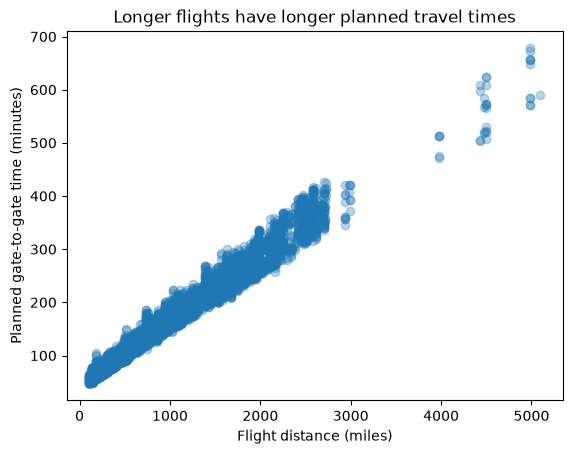

Correlation: 0.98
Strange flights: 0


In [9]:
# 10,000 random flights
sample = df.sample(10000, random_state=1)
plt.scatter(sample["DISTANCE"], sample["CRS_ELAPSED_TIME"], alpha=0.3)
plt.xlabel("Flight distance (miles)")
plt.ylabel("Planned gate-to-gate time (minutes)")
plt.title("Longer flights have longer planned travel times")
plt.show()

# correlation: 1 = perfect, 0 = no connection
print("Correlation:", round(df["DISTANCE"].corr(df["CRS_ELAPSED_TIME"]), 2))

# strange flights: over 1,500 miles but under 60 minutes (0 = none)
strange = df[(df["DISTANCE"] > 1500) & (df["CRS_ELAPSED_TIME"] < 60)]
print("Strange flights:", len(strange))

**Findings – Step 3:**
- Distance and planned gate-to-gate time go together: the longer the distance, the longer the planned time. The correlation is 0.98, so the two columns tell almost the same thing.
- We found no strange flights, such as a long distance with a very short planned time.

**Step 4 (Check 3): Does the data follow the rules? (Constraint and rule checking)**

In [10]:
# True = all flights follow the rule, False = some flights break it
# % 100 gives the last two digits of the time (the minutes)
rules = {
    "ARR_DEL15 is only 0 or 1": df["ARR_DEL15"].dropna().isin([0, 1]).all(),
    "CANCELLED is only 0 or 1": df["CANCELLED"].isin([0, 1]).all(),
    "DIVERTED is only 0 or 1": df["DIVERTED"].isin([0, 1]).all(),
    "All flights are from 2025": (df["FL_DATE"].dt.year == 2025).all(),
    "CRS_DEP_TIME is 0-2359": df["CRS_DEP_TIME"].between(0, 2359).all(),
    "CRS_DEP_TIME minutes < 60": (df["CRS_DEP_TIME"] % 100 < 60).all(),
    "CRS_ARR_TIME is 0-2359": df["CRS_ARR_TIME"].between(0, 2359).all(),
    "CRS_ARR_TIME minutes < 60": (df["CRS_ARR_TIME"] % 100 < 60).all(),
    "DISTANCE is above 0": (df["DISTANCE"] > 0).all(),
    "CRS_ELAPSED_TIME is above 0": (df["CRS_ELAPSED_TIME"] > 0).all(),
    "ORIGIN and DEST are different": (df["ORIGIN"] != df["DEST"]).all(),
    "No duplicate rows": not df.duplicated().any(),
}

for rule, ok in rules.items():
    print(ok, "-", rule)

True - ARR_DEL15 is only 0 or 1
True - CANCELLED is only 0 or 1
True - DIVERTED is only 0 or 1
True - All flights are from 2025
True - CRS_DEP_TIME is 0-2359
True - CRS_DEP_TIME minutes < 60
True - CRS_ARR_TIME is 0-2359
True - CRS_ARR_TIME minutes < 60
True - DISTANCE is above 0
True - CRS_ELAPSED_TIME is above 0
True - ORIGIN and DEST are different
True - No duplicate rows


**Findings – Step 4:**
We checked the rules that must always be true, for example:
- yes/no columns are only 0 or 1
- times are real clock times (00:00–23:59)
- distance and planned time are above 0
- a flight does not land at the same airport it left from
- no flight appears twice

All rules are **True**, so we found **no impossible values**.

We did not check that the arrival time is later than the departure time, because this is not true for many normal flights:
1. **Night flights** land after midnight. For example, a flight from Salt Lake City (SLC) to Atlanta (ATL) leaves at 23:35 and lands at 05:18.
2. **The times are local times.** A flight from Atlanta (ATL) to Los Angeles (LAX) leaves at 07:00 and lands at 08:33, but it is planned to take 273 minutes, because Los Angeles is 3 hours behind Atlanta.

The real planned travel time is in CRS_ELAPSED_TIME.

**Step 5 (Check 4): What is missing, and why? (Missingness analysis)**

In [11]:
# number of empty cells in each column
print(df.isna().sum())
print()

# are the flights with an empty target cancelled or diverted?
missing = df[df["ARR_DEL15"].isna()]
print("Flights with empty target:", len(missing))
print("Of these, cancelled:", int(missing["CANCELLED"].sum()))
print("Of these, diverted:", int(missing["DIVERTED"].sum()))

# share of flights with an empty target for each month (0.03 = 3%)
print()
print("Share of empty targets per month:")
print(df["ARR_DEL15"].isna().groupby(df["FL_DATE"].dt.month).mean().round(3))

FL_DATE                  0
OP_UNIQUE_CARRIER        0
ORIGIN                   0
DEST                     0
CRS_DEP_TIME             0
CRS_ARR_TIME             0
ARR_DEL15            13905
CANCELLED                0
DIVERTED                 0
CRS_ELAPSED_TIME         0
DISTANCE                 0
dtype: int64

Flights with empty target: 13905
Of these, cancelled: 11114
Of these, diverted: 2791

Share of empty targets per month:
FL_DATE
1     0.030
2     0.004
3     0.007
4     0.007
5     0.005
6     0.022
7     0.019
8     0.011
9     0.003
10    0.005
11    0.019
12    0.030
Name: ARR_DEL15, dtype: float64


**Findings – Step 5:**
- **How much is missing?** Only the target ARR_DEL15 is missing, for 13,905 flights (1.4%).
- **Which flights?** All of them were cancelled (11,114) or diverted (2,791). Missing target values are most common in January and December (3%).
- **Which type?** The missingness is systematic and can be explained by observed variables. Although this resembles MAR (Missing At Random), it is more appropriately described as structural missingness, because arrival delay at the scheduled destination is not meaningfully defined for these flights.
- **What we do:** We remove these flights in Section 4 rather than imputing artificial target values.
- **What it means for our results:** Our model predicts arrival delays conditional on flights being completed. It does not predict cancellations or diversions, which are unknown at the time of prediction.

**Summary – the 7 data quality dimensions**

| Dimension | What it asks | Our answer |
|---|---|---|
| Accuracy | Are the values correct? | Yes. The data comes from BTS, and all values look realistic (Check 1). |
| Completeness | Is anything missing? | Only the target, for 1.4% of the flights (Check 4). |
| Consistency | Is everything written the same way? | Yes. For example, all times are written as hhmm (Check 1). |
| Timeliness | Is the data recent enough? | Yes. 2025 is the newest full year. |
| Validity | Does the data follow the rules? | Yes. All rules are True, and there are no duplicates (Check 3). |
| Relevance | Does the data fit our question? | Yes. We only use information that is known before the flight leaves, plus the target. |
| Representativeness | Does the data show the full picture? | Mostly. The dataset covers Delta-operated domestic flights throughout 2025. However, excluding cancelled and diverted flights may underrepresent periods of severe operational disruption and limits the modelling population to completed flights. |

**Conclusion:** The data is in good shape. We found two things to fix in Section 4: the missing target for cancelled and diverted flights, and the hhmm format of the times.

## 4. Data wrangling

**The plan:**
1. Step 1 – Remove flights without a valid target.
2. Step 2 – Create new features from the date and scheduled times.
3. Step 3 – Validate the cleaned dataset.
Note on the date: FL_DATE was converted to a datetime format in Section 2 to support the data quality checks in Section 3.

Categorical encoding and numerical standardization are performed later within the preprocessing pipelines in Section 7.1. This ensures that preprocessing is fitted separately within each cross-validation training fold.

**Step 1: Remove the flights without a target**

In [12]:

# Keep only completed flights with a valid target
valid_status = (
    (df["CANCELLED"] == 0) &
    (df["DIVERTED"] == 0)
)

valid_target = df["ARR_DEL15"].isin([0, 1])

clean = df.loc[valid_status & valid_target].copy()

# Store the binary target as an integer
clean["ARR_DEL15"] = clean["ARR_DEL15"].astype(int)

print("Before:", len(df), "flights")
print("After:", len(clean), "flights")
print("Removed:", len(df) - len(clean), "flights")

Before: 1026332 flights
After: 1012427 flights
Removed: 13905 flights


**Findings – Step 1:**
We removed 13,905 cancelled or diverted flights without a valid arrival delay outcome. The final modelling population consists of 1,012,427 completed Delta flights.

This defines the scope of our model: predicting arrival delay risk for completed flights rather than predicting overall operational disruption. The original table df remains unchanged.

**Step 2: Make new features from the date and the times**

In [13]:
# month (1 = January, 12 = December) and weekday (1 = Monday, 7 = Sunday) from the date
clean["MONTH"] = clean["FL_DATE"].dt.month
clean["DAY_OF_WEEK"] = clean["FL_DATE"].dt.dayofweek + 1

# scheduled departure and arrival as minutes after midnight
# // 100 gives the hours and % 100 gives the minutes: 1430 -> 14 * 60 + 30 = 870
clean["DEP_MINUTES"] = (clean["CRS_DEP_TIME"] // 100) * 60 + clean["CRS_DEP_TIME"] % 100
clean["ARR_MINUTES"] = (clean["CRS_ARR_TIME"] // 100) * 60 + clean["CRS_ARR_TIME"] % 100

# show 5 flights, to check that the new columns look right
display(clean[["FL_DATE", "MONTH", "DAY_OF_WEEK", "CRS_DEP_TIME", "DEP_MINUTES", "CRS_ARR_TIME", "ARR_MINUTES"]].head())

,FL_DATE,MONTH,DAY_OF_WEEK,CRS_DEP_TIME,DEP_MINUTES,CRS_ARR_TIME,ARR_MINUTES
0,2025-01-01,1,3,635,395,1132,692
1,2025-01-01,1,3,1135,695,1633,993
2,2025-01-01,1,3,800,480,1139,699
3,2025-01-01,1,3,605,365,859,539
4,2025-01-01,1,3,1413,853,1705,1025


**Findings – Step 2:** We made four new features:
- **MONTH** and **DAY_OF_WEEK** from the date, to capture seasons and weekdays.
- **DEP_MINUTES** and **ARR_MINUTES** from the scheduled times, as minutes after midnight. Now 15:59 is 959 and 16:00 is 960, so they are exactly one minute apart, just like in real life.

**Step 3: Validate the cleaned dataset**

**What we do:** We check the size, completeness and consistency of the dataset after cleaning and feature engineering.

**Why:** We need to ensure that the modelling population contains valid target values and that the engineered predictors follow their expected ranges.

In [14]:
# Validate the cleaned dataset
print("Rows and columns:", clean.shape)
print("Empty cells in total:", clean.isna().sum().sum())

print("\nTarget distribution:")
display(
    clean["ARR_DEL15"]
    .value_counts(normalize=True)
    .round(4)
)

# Validate engineered features
checks = {
    "MONTH is 1–12":
        clean["MONTH"].between(1, 12).all(),

    "DAY_OF_WEEK is 1–7":
        clean["DAY_OF_WEEK"].between(1, 7).all(),

    "DEP_MINUTES is 0–1439":
        clean["DEP_MINUTES"].between(0, 1439).all(),

    "ARR_MINUTES is 0–1439":
        clean["ARR_MINUTES"].between(0, 1439).all(),

    "Valid target":
        clean["ARR_DEL15"].isin([0, 1]).all(),

    "No cancelled or diverted flights":
        (clean[["CANCELLED", "DIVERTED"]] == 0).all().all(),

    "Valid airport codes":
        clean[["ORIGIN", "DEST"]].notna().all().all()
}

display(pd.Series(checks, name="Passed"))

# Check the number of airport categories
print("Unique origin airports:",
      clean["ORIGIN"].nunique())

print("Unique destination airports:",
      clean["DEST"].nunique())

assert all(checks.values()), "Data validation failed"

Rows and columns: (1012427, 15)
Empty cells in total: 0

Target distribution:


ARR_DEL15
0    0.8021
1    0.1979
Name: proportion, dtype: float64

MONTH is 1–12                       True
DAY_OF_WEEK is 1–7                  True
DEP_MINUTES is 0–1439               True
ARR_MINUTES is 0–1439               True
Valid target                        True
No cancelled or diverted flights    True
Valid airport codes                 True
Name: Passed, dtype: bool

Unique origin airports: 153
Unique destination airports: 153


**Findings – Step 3:**

- The cleaned dataset contains 1,012,427 completed flights and 15 columns, consisting of the 11 original variables and four engineered temporal features.
- No missing values remain.
- Approximately 19.8% of the completed flights are delayed, while 80.2% are not delayed.
- All validation checks are satisfied.
- ORIGIN and DEST each contain 153 unique airport categories.
- The airport variables are retained in their original categorical format until preprocessing within the modelling pipelines.

## 5. Preparing the data for the models

**The plan:**
1. Step 1 – Select the predictors (X) and the target variable (y).
2. Step 2 – Split the data into training and test sets.

We retain the original numerical and categorical predictors at this stage. One-Hot Encoding and standardization are performed within the modelling pipelines in Section 7.1.

**Step 1: Choose the features (X) and the target (y)**

In [15]:
# Numerical predictors
NUMERIC_FEATURES = [
    "MONTH",
    "DAY_OF_WEEK",
    "DEP_MINUTES",
    "ARR_MINUTES",
    "CRS_ELAPSED_TIME",
    "DISTANCE"
]

# Categorical predictors
CATEGORICAL_FEATURES = [
    "ORIGIN",
    "DEST"
]

# Combine the eight original predictors
RAW_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Define predictors and target
X = clean[RAW_FEATURES].copy()
y = clean["ARR_DEL15"].copy()

print("X:", X.shape)
print("y:", y.shape)
print("Numerical predictors:", len(NUMERIC_FEATURES))
print("Categorical predictors:", len(CATEGORICAL_FEATURES))

display(X.head())

X: (1012427, 8)
y: (1012427,)
Numerical predictors: 6
Categorical predictors: 2


,MONTH,DAY_OF_WEEK,DEP_MINUTES,ARR_MINUTES,CRS_ELAPSED_TIME,DISTANCE,ORIGIN,DEST
0,1,3,395,692,177.0,1269.0,ABQ,ATL
1,1,3,695,993,178.0,1269.0,ABQ,ATL
2,1,3,480,699,159.0,981.0,ABQ,MSP
3,1,3,365,539,174.0,853.0,ALB,ATL
4,1,3,853,1025,172.0,853.0,ALB,ATL


**Findings – Step 1:**

- The predictor matrix contains eight pre-departure flight characteristics: six numerical and two categorical predictors.
- All selected predictors are available before scheduled departure.
- The target variable is ARR_DEL15, where 1 represents an arrival delay of at least 15 minutes and 0 represents an arrival delay below 15 minutes.
- DISTANCE and CRS_ELAPSED_TIME are highly correlated (0.98). Both are initially retained for modelling.
- ORIGIN and DEST will be One-Hot Encoded within the preprocessing pipelines.

**Step 2: Split the flights into a training set and a test set**

In [16]:

from sklearn.model_selection import train_test_split

# 95% for training and 5% for testing
# Given our large dataset, 5% still provides a substantial
# test set for final model evaluation.
# Stratification preserves the target distribution.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=42, stratify=y
)

# Check the sizes of the two datasets
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# Check the proportion of delayed flights
print("Share of late flights in training set:",
      round(y_train.mean(), 3))

print("Share of late flights in test set:",
      round(y_test.mean(), 3))

X_train: (961805, 8)
X_test: (50622, 8)
Share of late flights in training set: 0.198
Share of late flights in test set: 0.198


**Findings – Step 2:**
Training set: 961,805 flights (95%).

Test set: 50,622 flights (5%).

Class distribution: By using stratify=y, approximately 19.8% of the flights are delayed in both sets.

Choice of split: Given our large dataset of over one million observations, we use a 95/5 split rather than the conventional 70/30 split. This allows us to retain more observations for model training while maintaining a substantial test set for final evaluation (Ng, 2018; Pargent et al., 2023).

Limitation: The split is random, so flights from the same day may appear in both sets. Shared operational conditions may therefore result in optimistic estimates of performance on future periods.

Validation: Model selection and hyperparameter tuning will be conducted using 3-fold stratified cross-validation within the training set. The test set is reserved for final evaluation.


## 6. Exploratory Data Analysis – Delay patterns

In Section 3, we examined the quality of our data. In this section, we investigate patterns in flight delays that are relevant to our machine learning question.

**The plan:**

1. Delay rate by month
2. Delay rate by day of week
3. Delay rate by scheduled departure hour
4. Delay rate by origin and destination airport
5. Interaction between month and departure hour

The purpose is to identify potentially informative predictors and explore relationships that our machine learning models may be able to capture.

We conduct these analyses using the training set only to avoid using test data for modelling decisions. The identified patterns represent associations rather than causal relationships.

In [122]:
# Use training data only for EDA
eda = clean.loc[X_train.index, [
    "MONTH", "DAY_OF_WEEK", "DEP_MINUTES",
    "ORIGIN", "DEST", "ARR_DEL15"
]].copy()

# Create departure hour for visualisation
eda["DEP_HOUR"] = eda["DEP_MINUTES"] // 60

# Calculate overall delay rate
overall_delay = eda["ARR_DEL15"].mean() * 100

print("Number of flights:", len(eda))
print("Overall delay rate:", round(overall_delay, 2), "%")

Number of flights: 961805
Overall delay rate: 19.79 %


### 6.1 Delay rate by month

**What we do:** We compare the proportion of delayed flights across the twelve months of 2025.

**Why:** Delay risk may vary throughout the year. This analysis helps us investigate whether MONTH is a potentially useful predictor.

,flights,delay_rate,delay_rate_pct
MONTH,,,
1,70338,0.19,19.36
2,67420,0.20,19.92
3,79744,0.18,18.45
4,79366,0.18,17.76
5,84880,0.22,22.02
6,84832,0.26,26.13
7,87674,0.25,24.86
8,84805,0.17,17.05
9,80464,0.12,12.42


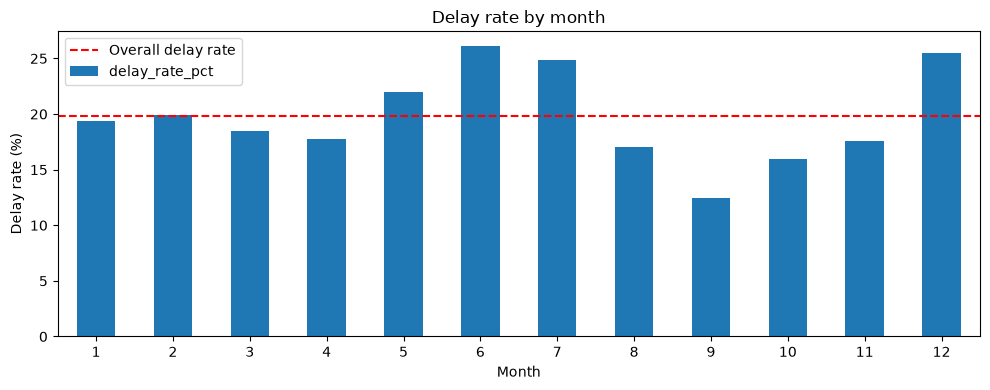

Highest delay rate: 6
Delay rate (%): 26.13
Lowest delay rate: 9
Delay rate (%): 12.42


In [123]:
monthly = eda.groupby("MONTH")["ARR_DEL15"].agg(
    flights="size",
    delay_rate="mean"
)

monthly["delay_rate_pct"] = monthly["delay_rate"] * 100

display(monthly.round(2))

monthly["delay_rate_pct"].plot(
    kind="bar", figsize=(10, 4)
)

plt.axhline(
    overall_delay, color="red",
    linestyle="--", label="Overall delay rate"
)

plt.title("Delay rate by month")
plt.xlabel("Month")
plt.ylabel("Delay rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

print("Highest delay rate:", monthly["delay_rate_pct"].idxmax())
print("Delay rate (%):", round(monthly["delay_rate_pct"].max(), 2))

print("Lowest delay rate:", monthly["delay_rate_pct"].idxmin())
print("Delay rate (%):", round(monthly["delay_rate_pct"].min(), 2))

**Findings – 6.1:**

- The highest delay rate was observed in June (26.13%).
- The lowest delay rate was observed in September (12.42%).
- Delay rates are also high in July (24.86%) and December (25.50%), while August–November sit at or below the overall rate of 19.79%.
- Differences in delay rates across months suggest that MONTH may be a useful predictor.
- However, since we only have data from 2025, we cannot determine whether these patterns repeat every year.

### 6.2 Delay rate by day of week

**What we do:** We compare the proportion of delayed flights across the seven days of the week.

**Why:** Flight demand and operational conditions may differ between weekdays and weekends. This analysis helps us investigate whether DAY_OF_WEEK is a potentially useful predictor.

,flights,delay_rate,delay_rate_pct
DAY_OF_WEEK,,,
Monday,143262,0.21,21.43
Tuesday,136021,0.17,16.62
Wednesday,137532,0.16,16.14
Thursday,141928,0.20,19.83
Friday,140947,0.20,20.39
Saturday,121610,0.19,19.21
Sunday,140505,0.25,24.64


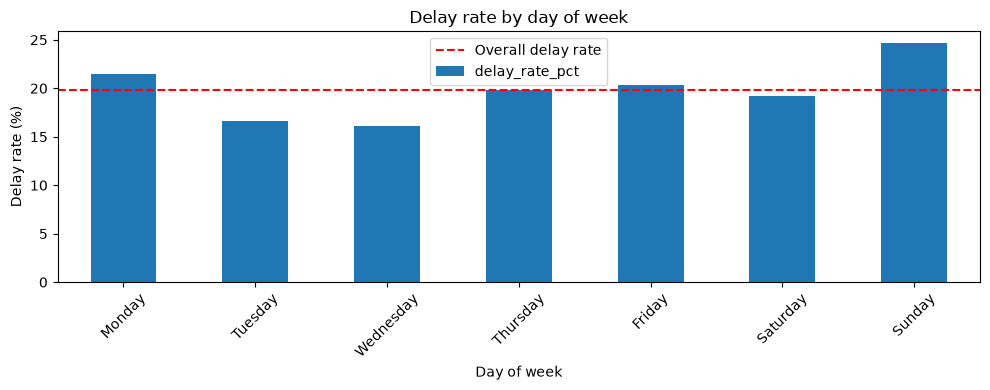

Highest delay rate: Sunday
Lowest delay rate: Wednesday


In [124]:
weekday = eda.groupby("DAY_OF_WEEK")["ARR_DEL15"].agg(
    flights="size",
    delay_rate="mean"
)

weekday["delay_rate_pct"] = weekday["delay_rate"] * 100

weekday = weekday.rename(index={
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
})

display(weekday.round(2))

weekday["delay_rate_pct"].plot(
    kind="bar", figsize=(10, 4)
)

plt.axhline(
    overall_delay, color="red",
    linestyle="--", label="Overall delay rate"
)

plt.title("Delay rate by day of week")
plt.xlabel("Day of week")
plt.ylabel("Delay rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print("Highest delay rate:", weekday["delay_rate_pct"].idxmax())
print("Lowest delay rate:", weekday["delay_rate_pct"].idxmin())

**Findings – 6.2:**

- The highest delay rate was observed on Sunday (24.64%).
- The lowest delay rate was observed on Wednesday (16.14%).
- Monday (21.43%) and Friday (20.39%) are also above the overall rate, while Tuesday and Wednesday are clearly below it.
- Delay risk therefore varies across the week, which suggests that DAY_OF_WEEK may contribute to predictive performance.

### 6.3 Delay rate by scheduled departure hour

**What we do:** We compare delay rates across scheduled departure hours.

**Why:** Operational disruptions may accumulate throughout the day. We investigate whether flights scheduled later in the day are associated with a higher probability of arriving late.

,flights,delay_rate,delay_rate_pct
DEP_HOUR,,,
0,2051,0.14,13.94
1,483,0.18,17.60
3,16,0.25,25.00
5,24608,0.08,8.05
6,66316,0.09,9.25
7,83517,0.12,12.07
8,61556,0.13,13.50
9,50733,0.15,14.59
10,53458,0.16,15.73


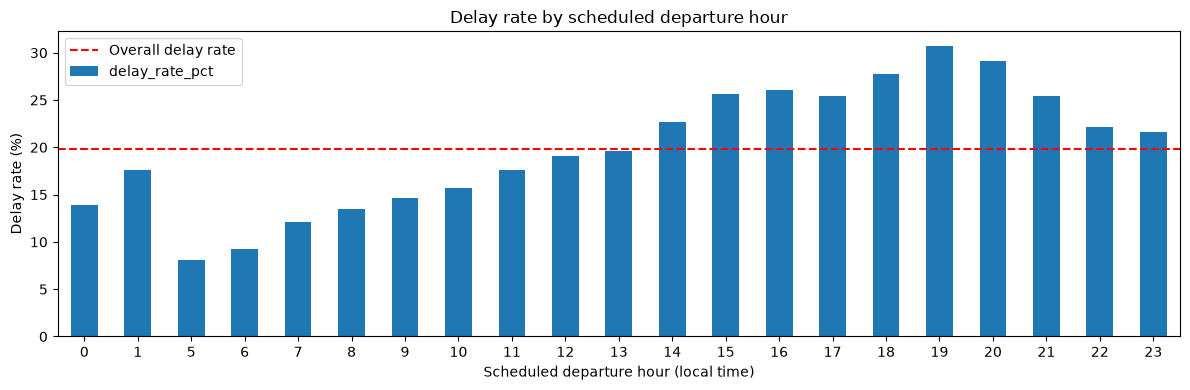

Highest delay rate: 19
Lowest delay rate: 5


In [125]:
hourly = eda.groupby("DEP_HOUR")["ARR_DEL15"].agg(
    flights="size",
    delay_rate="mean"
)

hourly["delay_rate_pct"] = hourly["delay_rate"] * 100

display(hourly.round(2))

# Only visualise hours with at least 100 flights
hourly_plot = hourly[hourly["flights"] >= 100]

hourly_plot["delay_rate_pct"].plot(
    kind="bar", figsize=(12, 4)
)

plt.axhline(
    overall_delay, color="red",
    linestyle="--", label="Overall delay rate"
)

plt.title("Delay rate by scheduled departure hour")
plt.xlabel("Scheduled departure hour (local time)")
plt.ylabel("Delay rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

print("Highest delay rate:", hourly_plot["delay_rate_pct"].idxmax())
print("Lowest delay rate:", hourly_plot["delay_rate_pct"].idxmin())

**Findings – 6.3:**

- Among hours with at least 100 flights, the highest delay rate was observed at 19:00 (30.72%).
- The lowest delay rate was observed at 05:00 (8.05%).
- Delay risk rises steadily through the day: morning departures (05:00–09:00) stay well below the overall rate, while afternoon and evening departures (from about 14:00) are clearly above it.
- This pattern suggests that scheduled departure time (DEP_MINUTES) is likely a useful predictor.

### 6.4 Delay rate by origin and destination airport

**What we do:** We compare delay rates across origin and destination airports.

**Why:** Airports may differ in terms of congestion, traffic volume and operational conditions. We investigate whether airport characteristics are associated with different levels of delay risk.

To avoid overinterpreting airports with very few observations, we only visualise airports with at least 1,000 flights in the training data.

Highest delay rates by ORIGIN


,flights,delay_rate,delay_rate_pct
ORIGIN,,,
EWR,6080,0.29,29.14
MIA,10422,0.27,27.11
LGA,27053,0.27,27.09
ORD,10353,0.26,25.94
BOS,24165,0.24,24.33
MCO,19534,0.24,23.86
FLL,11775,0.24,23.78
PBI,6670,0.23,23.48
ATL,221827,0.23,23.08


Lowest delay rates by ORIGIN


,flights,delay_rate,delay_rate_pct
ORIGIN,,,
ONT,1695,0.08,8.32
SJC,2316,0.09,8.85
TUS,1044,0.09,9.20
SMF,3280,0.10,9.57
MSN,1642,0.10,9.93
PNS,2607,0.10,10.43
ABQ,1099,0.10,10.46
PDX,6847,0.11,10.90
GSP,2769,0.11,11.20


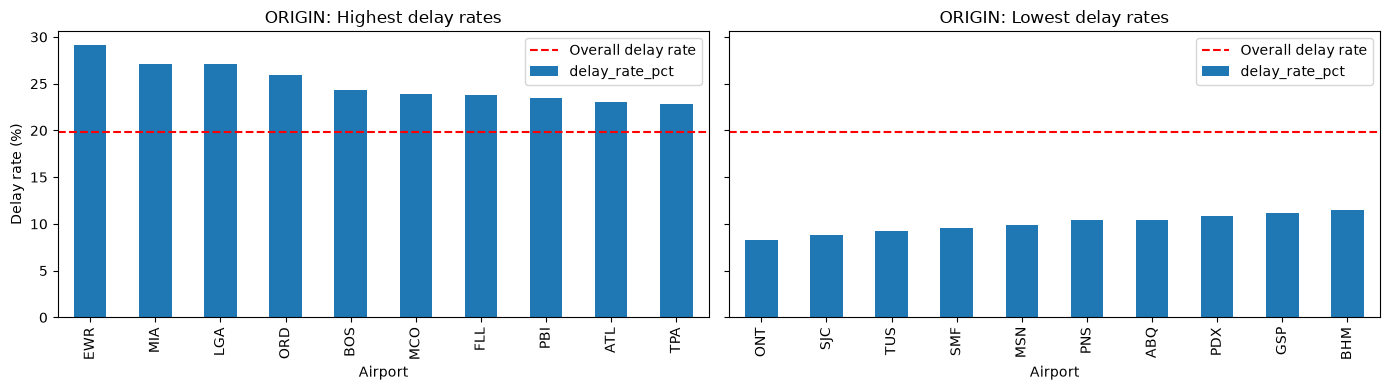

Highest delay rates by DEST


,flights,delay_rate,delay_rate_pct
DEST,,,
EWR,6033,0.35,34.81
DCA,8622,0.30,29.54
ORD,10310,0.28,28.50
PBI,6753,0.28,28.36
PVD,1156,0.28,28.03
MIA,10495,0.28,27.69
ALB,1209,0.28,27.54
DFW,11228,0.27,27.29
DEN,10850,0.27,27.20


Lowest delay rates by DEST


,flights,delay_rate,delay_rate_pct
DEST,,,
OGG,1121,0.14,13.74
SLC,51530,0.15,15.20
SEA,30125,0.16,16.06
ATL,221758,0.16,16.39
DAY,1295,0.17,16.53
IND,4135,0.17,16.57
ICT,1050,0.17,16.86
VPS,2473,0.17,17.02
DAB,1477,0.17,17.06


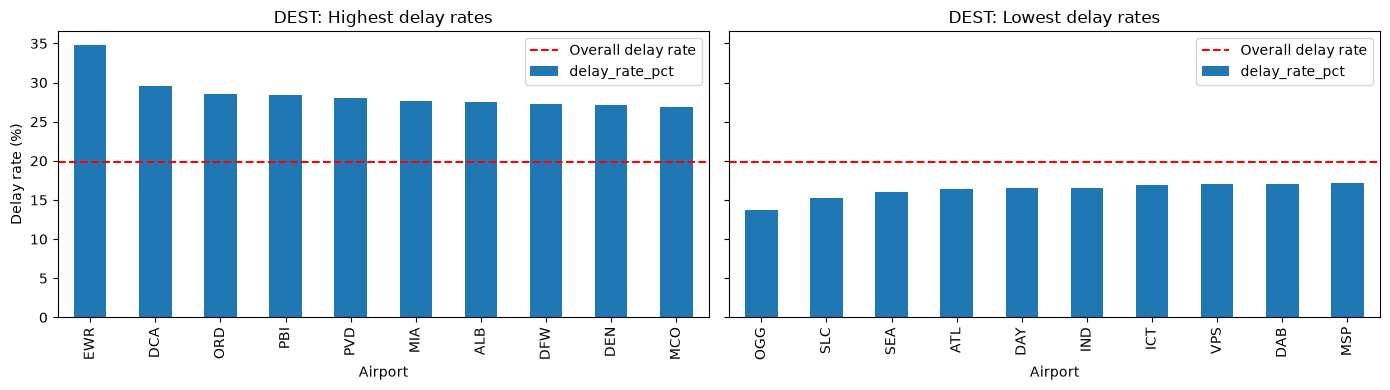

In [126]:
for airport in ["ORIGIN", "DEST"]:

    airport_summary = eda.groupby(airport)["ARR_DEL15"].agg(
        flights="size",
        delay_rate="mean"
    )

    airport_summary = airport_summary[
        airport_summary["flights"] >= 1000
    ].copy()

    airport_summary["delay_rate_pct"] = (
        airport_summary["delay_rate"] * 100
    )

    top_10 = airport_summary.nlargest(10, "delay_rate_pct")
    bottom_10 = airport_summary.nsmallest(10, "delay_rate_pct")

    print(f"Highest delay rates by {airport}")
    display(top_10.round(2))

    print(f"Lowest delay rates by {airport}")
    display(bottom_10.round(2))

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 4), sharey=True
    )

    top_10["delay_rate_pct"].plot(
        kind="bar", ax=axes[0]
    )

    bottom_10["delay_rate_pct"].plot(
        kind="bar", ax=axes[1]
    )

    axes[0].set_title(f"{airport}: Highest delay rates")
    axes[1].set_title(f"{airport}: Lowest delay rates")

    for ax in axes:
        ax.axhline(
            overall_delay, color="red",
            linestyle="--", label="Overall delay rate"
        )
        ax.set_ylabel("Delay rate (%)")
        ax.set_xlabel("Airport")
        ax.legend()

    plt.tight_layout()
    plt.show()

**Findings – 6.4:**

- Among the origin airports with at least 1,000 observations, EWR has the highest delay rate (29.14%), while ONT has the lowest (8.32%).
- Among the destination airports, EWR has the highest delay rate (34.81%), while OGG has the lowest (13.74%).
- Other high-delay origins include MIA, LGA and ORD; other high-delay destinations include DCA, ORD and PBI.
- Differences between airports may indicate that ORIGIN and DEST contain useful predictive information.
- These differences should not be interpreted as causal effects, as airports may differ in other characteristics such as flight schedules, routes and weather conditions.

### 6.5 Interaction between month and departure hour

**What we do:** We create a heatmap showing delay rates for combinations of month and scheduled departure hour.

**Why:** The relationship between departure time and delay risk may differ across months. This analysis helps us investigate potential interactions between predictors, rather than examining each variable independently.

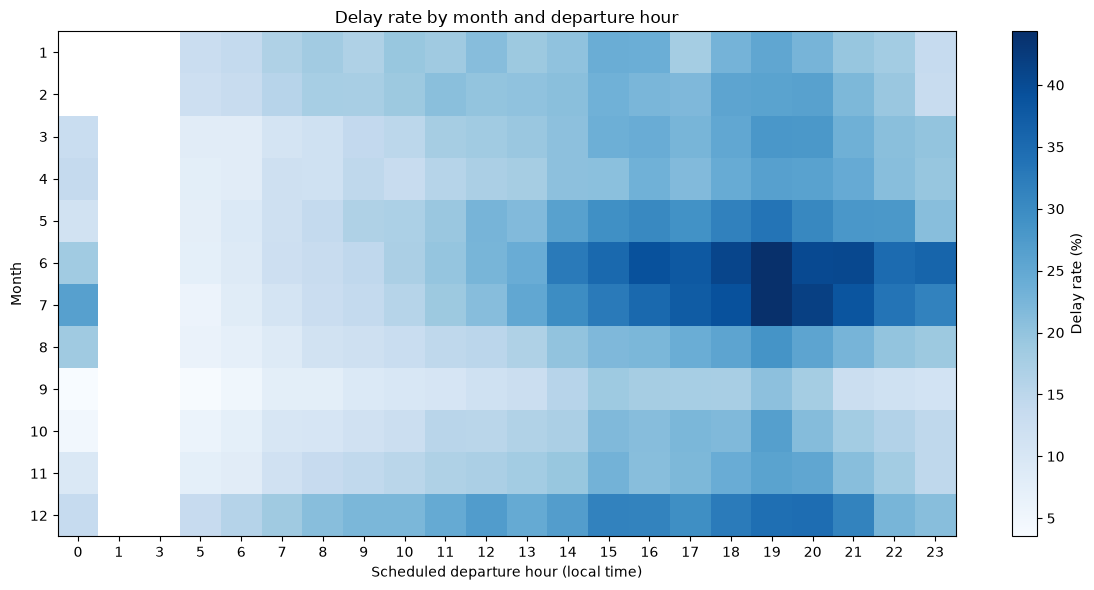

In [127]:
# Calculate the delay rate for each combination
delay_matrix = eda.pivot_table(
    index="MONTH",
    columns="DEP_HOUR",
    values="ARR_DEL15",
    aggfunc="mean"
) * 100

# Count flights in each combination
flight_counts = eda.pivot_table(
    index="MONTH",
    columns="DEP_HOUR",
    values="ARR_DEL15",
    aggfunc="size"
)

# Hide combinations with fewer than 100 flights
delay_matrix = delay_matrix.where(flight_counts >= 100)

plt.figure(figsize=(12, 6))

plt.imshow(
    delay_matrix, aspect="auto", cmap="Blues"
)

plt.colorbar(label="Delay rate (%)")

plt.xticks(
    range(len(delay_matrix.columns)),
    delay_matrix.columns
)

plt.yticks(
    range(len(delay_matrix.index)),
    delay_matrix.index
)

plt.xlabel("Scheduled departure hour (local time)")
plt.ylabel("Month")
plt.title("Delay rate by month and departure hour")

plt.tight_layout()
plt.show()

**Findings – 6.5:**

- Across months, delay rates are generally lowest in the early morning and rise towards the late afternoon and evening.
- The daily pattern is not the same in every month: evening delay rates are especially high in June, July and December (often above 30–40%), while September and October stay comparatively low even later in the day.
- Because the relationship between departure hour and delay risk differs across months, this suggests a potential interaction between MONTH and DEP_MINUTES.
- Such interactions motivate the use of tree-based models, which can capture complex relationships between predictors without explicitly specifying interaction terms.

### 6.6 Summary of EDA findings

The exploratory data analysis investigates how arrival delay risk varies across calendar months, weekdays, scheduled departure hours and airports. In the training data (961,805 flights from the 95/5 split), the overall delay rate is 19.79%.

- **Month:** Delay rates range from 12.42% in September to 26.13% in June, with July and December also high.
- **Day of week:** Sunday has the highest delay rate (24.64%) and Wednesday the lowest (16.14%).
- **Departure hour:** Delay risk rises through the day, from 8.05% at 05:00 to 30.72% at 19:00.
- **Airports:** Among airports with at least 1,000 flights, EWR has the highest delay rates as both origin (29.14%) and destination (34.81%); ONT and OGG have the lowest.
- **Interaction:** Evening delay risk is much stronger in June, July and December than in September–October, which points to a potential interaction between MONTH and DEP_MINUTES.

These patterns support keeping MONTH, DAY_OF_WEEK, DEP_MINUTES, ORIGIN and DEST as predictors. Potential non-linear relationships and interactions motivate the comparison of Logistic Regression, Decision Tree and Random Forest.

All analyses in this section are based on the training data. The identified relationships are descriptive associations and should not be interpreted as causal effects. Whether these predictors contribute to generalizable predictive performance will be investigated in the following modelling section.

## 7. Modelling

In the previous sections, we collected, explored and prepared the data for modelling. Our exploratory data analysis identified patterns in arrival delays across months, weekdays, scheduled departure hours and airports.

We now investigate whether supervised machine learning models can use these characteristics to predict whether a Delta-operated flight will arrive at least 15 minutes late.

**The plan:**

1. Modelling strategy and validation
2. Baseline – DummyClassifier
3. Logistic Regression
4. Decision Tree
5. Random Forest
6. Overfitting and model generalization
7. Hyperparameter tuning
8. Summary of selected models

We compare models with different levels of complexity to investigate whether more complex models provide better predictive performance than simpler alternatives.

All model selection and hyperparameter tuning are conducted using the training data. The test set is reserved for final model evaluation in Section 8.

### 7.1 Modelling strategy and validation

**What we do:** We establish a common training and validation strategy for all classification models.

**Why:** To ensure a fair comparison, all models are trained and validated using the same observations and evaluation metrics.

As established in Section 5, we use a 95/5 stratified train/test split. The training set contains 961,805 flights, while the test set contains 50,622 flights. Given the large dataset, this allocation allows us to maximize the amount of data available for model development while retaining a substantial independent holdout set for final evaluation.

We use 3-fold stratified cross-validation within the training set to estimate how well the models generalize to unseen observations. Stratification preserves the proportion of delayed and non-delayed flights across the folds.

**Evaluation metrics:**

- Accuracy: the proportion of correctly classified flights.
- Precision: the proportion of predicted delayed flights that are actually delayed.
- Recall: the proportion of actual delayed flights that are correctly identified.
- F1-score: the harmonic mean of precision and recall.
- ROC-AUC: the model's ability to distinguish between delayed and non-delayed flights across classification thresholds.

Due to the imbalanced target distribution, accuracy alone is insufficient. We use ROC-AUC as our primary metric for model selection, while precision, recall and F1-score help us understand the practical consequences of classification errors.

In [18]:
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, GridSearchCV
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import make_scorer, precision_score

# Use the same cross-validation strategy for all models
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, zero_division=0
    ),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Number of CV folds:", cv.get_n_splits())
print("Training observations:", len(y_train))
print("Test observations:", len(y_test))

Number of CV folds: 3
Training observations: 961805
Test observations: 50622


#### Preprocessing pipelines

**What we do:** We define separate preprocessing pipelines for Logistic Regression and tree-based models.

**Why:** Preprocessing must be fitted independently within each cross-validation training fold to prevent information from the validation fold from influencing the training process.

- **One-Hot Encoding:** ORIGIN and DEST are nominal categorical variables without a natural order. They are converted into binary indicators using OneHotEncoder.
- **Standardization:** The numerical predictors are standardized for Logistic Regression because their original scales differ substantially.
- **Tree-based models:** Decision Tree and Random Forest do not require standardization, as they rely on splitting observations according to predictor values.
- **Unknown categories:** Previously unseen airport categories are handled using `handle_unknown="ignore"`.

The preprocessing pipelines ensure that all transformations are fitted using training observations only.

In [19]:
# The predictors are already in their original format
X_train_raw = X_train
X_test_raw = X_test

# Preprocessing for Logistic Regression
preprocessor_scaled = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        NUMERIC_FEATURES
    ),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        CATEGORICAL_FEATURES
    )
])

# Preprocessing for Decision Tree and Random Forest
preprocessor_unscaled = ColumnTransformer([
    (
        "numeric",
        "passthrough",
        NUMERIC_FEATURES
    ),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        CATEGORICAL_FEATURES
    )
])

print("Training data:", X_train_raw.shape)
print("Test data:", X_test_raw.shape)

Training data: (961805, 8)
Test data: (50622, 8)


In [130]:
# Store validation results for each model
model_results = {}

# Common evaluation function
def evaluate_model(name, model, X_data, y_data):

    scores = cross_validate(
        model,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1
    )

    results = {
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC SD": scores["test_roc_auc"].std(),
        "Training ROC-AUC": scores["train_roc_auc"].mean()
    }

    # Difference between training and validation performance
    results["Generalization gap"] = (
        results["Training ROC-AUC"] - results["ROC-AUC"]
    )

    model_results[name] = results

    display(pd.DataFrame([results], index=[name]).round(4))

    return scores

In [131]:
# Display results for selected models
def compare_models(names=None):

    results = pd.DataFrame.from_dict(
        model_results,
        orient="index"
    )

    results.index.name = "Model"

    if names is not None:
        results = results.loc[names]

    display(results.round(4))

    return results

### 7.2 Baseline – DummyClassifier

**What we do:** We establish a simple baseline using a DummyClassifier with the most_frequent strategy.

**Why:** We need a reference point to determine whether our machine learning models provide predictive value beyond a simple majority-class prediction.

The DummyClassifier always predicts the most frequent class without learning relationships between the predictors and the target.

Since approximately 80.2% of our flights are not delayed, we expect the baseline to achieve relatively high accuracy despite being unable to identify delayed flights.

This demonstrates why accuracy alone can be misleading when evaluating classification models on imbalanced data.

In [132]:
# Create a majority-class baseline
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Evaluate using 3-fold cross-validation
dummy_scores = evaluate_model(
    "DummyClassifier",
    dummy_model,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
DummyClassifier,0.8021,0.0,0.0,0.0,0.5,0.0,0.5,0.0


**Findings – 7.2:**

- The DummyClassifier achieves an accuracy of approximately 80.2%, reflecting the proportion of non-delayed flights.
- The model does not identify any delayed flights, resulting in a recall and F1-score of 0. Precision is undefined because there are no positive predictions and is therefore reported as 0.
- The ROC-AUC is 0.50, meaning that the model cannot distinguish between delayed and non-delayed flights.
- Despite its high accuracy, the model provides no useful information for identifying flights at increased risk of delay.
- These results establish a baseline against which the remaining machine learning models can be evaluated.

### 7.3 Logistic Regression

**What we do:** We train a Logistic Regression model to estimate the probability that a flight arrives at least 15 minutes late.

**Why:** Logistic Regression is a relatively simple and interpretable parametric classification model. It allows us to investigate whether our selected predictors contain useful information about arrival delay risk.

The model transforms a linear combination of the predictors into a probability between 0 and 1 using the logistic function.

We standardize the numerical predictors and apply One-Hot Encoding to the categorical predictors within a Pipeline.

We first train a standard Logistic Regression model and subsequently investigate whether balanced class weights improve the identification of delayed flights.

#### 7.3.1 Standard Logistic Regression

We first train a Logistic Regression model without class weighting, using L2 regularization and the default regularization strength of C = 1.

This allows us to establish an initial performance estimate before investigating class weighting and hyperparameter tuning.

In [133]:
# Standard Logistic Regression
logistic_model = Pipeline([
    ("preprocessing", preprocessor_scaled),

    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

# Evaluate using cross-validation
logistic_scores = evaluate_model(
    "Logistic Regression",
    logistic_model,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Logistic Regression,0.802,0.4383,0.0012,0.0025,0.6435,0.0008,0.645,0.0015


#### 7.3.2 Logistic Regression with balanced class weights

**What we do:** We train a second Logistic Regression model using balanced class weights.

**Why:** Delayed flights represent only approximately 19.8% of our observations. The standard model may therefore struggle to identify delayed flights at the default classification threshold.

Balanced class weighting assigns greater weight to the minority class during training. This changes the importance of classification errors in the loss function without changing the number of observations.

We investigate whether this improves recall and how it affects precision, F1-score and ROC-AUC.

In [134]:
# Logistic Regression with balanced class weights
logistic_balanced = Pipeline([
    ("preprocessing", preprocessor_scaled),

    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Evaluate using cross-validation
logistic_balanced_scores = evaluate_model(
    "Logistic Regression (balanced)",
    logistic_balanced,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Logistic Regression (balanced),0.6033,0.2734,0.6057,0.3768,0.6437,0.0007,0.6452,0.0016


#### 7.3.3 Comparison of Logistic Regression models

We compare standard and balanced Logistic Regression using the same cross-validation folds and evaluation metrics.

The purpose is to isolate the effect of class weighting on discriminative performance and classification behaviour.

In [135]:
# Compare Logistic Regression configurations
lr_comparison = compare_models([
    "Logistic Regression",
    "Logistic Regression (balanced)"
])

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Model,,,,,,,,
Logistic Regression,0.8020,0.4383,0.0012,0.0025,0.6435,0.0008,0.6450,0.0015
Logistic Regression (balanced),0.6033,0.2734,0.6057,0.3768,0.6437,0.0007,0.6452,0.0016


**Findings – 7.3:**

- Standard Logistic Regression achieves a validation ROC-AUC of 0.6435, outperforming the DummyClassifier baseline of 0.50.
- Despite an accuracy of 80.20%, the standard model identifies only 0.12% of delayed flights at the default classification threshold.
- Balanced class weighting increases recall from 0.0012 to 0.6057 and F1-score from 0.0025 to 0.3768, while precision decreases from 0.4383 to 0.2734.
- ROC-AUC remains almost unchanged, suggesting that class weighting primarily affects classification behaviour rather than discriminative performance.
- Further investigation of regularization and model performance will be conducted in Sections 7.6 and 7.7.

### 7.4 Decision Tree

**What we do:** We train a Decision Tree classifier to predict whether a flight arrives at least 15 minutes late.

**Why:** Unlike Logistic Regression, Decision Trees can capture non-linear relationships and interactions between predictors without explicitly specifying them.

Our exploratory data analysis in Section 6 revealed that delay rates vary across scheduled departure hours, months and airports. In particular, the heatmap suggests a potential interaction between month and departure time.

A Decision Tree recursively divides the data into smaller groups based on predictor values, aiming to create groups with increasingly similar target values.

We first train a standard Decision Tree with limited depth and subsequently investigate whether balanced class weights improve the identification of delayed flights.

Since Decision Trees are based on splitting observations rather than calculating distances or linear combinations, standardization of numerical predictors is not required.

#### 7.4.1 Standard Decision Tree

We first train a Decision Tree using Gini impurity as the splitting criterion and a maximum depth of 5.

Limiting the depth controls model complexity and reduces the risk of overfitting. We initially use no class weighting to establish a reference point before investigating the effect of balanced class weights.

As with Logistic Regression, we evaluate the model using 3-fold stratified cross-validation.

In [136]:
# Standard Decision Tree
tree_model = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    ))
])

# Evaluate using cross-validation
tree_scores = evaluate_model(
    "Decision Tree",
    tree_model,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Decision Tree,0.8021,0.3851,0.0001,0.0003,0.6433,0.0015,0.6443,0.001


#### 7.4.2 Decision Tree with balanced class weights

**What we do:** We train a second Decision Tree using balanced class weights.

**Why:** The Logistic Regression results demonstrated that class weighting substantially improved recall, while ROC-AUC remained almost unchanged.

We investigate whether a similar pattern occurs for the Decision Tree model.

Balanced class weighting increases the influence of delayed flights when calculating impurity and selecting splits. This may affect both the structure of the tree and its classification behaviour.

We keep the remaining hyperparameters unchanged to isolate the effect of class weighting.

In [137]:
# Decision Tree with balanced class weights
tree_balanced = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Evaluate using cross-validation
tree_balanced_scores = evaluate_model(
    "Decision Tree (balanced)",
    tree_balanced,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Decision Tree (balanced),0.6122,0.2754,0.5874,0.3749,0.6428,0.0016,0.6437,0.001


#### 7.4.3 Comparison of Decision Tree models

We compare the standard and balanced Decision Tree configurations to investigate the effect of class weighting.

Both models use a maximum depth of 5 and are evaluated using the same cross-validation strategy.

In [138]:
# Compare initial Decision Tree configurations
dt_comparison = compare_models([
    "Decision Tree",
    "Decision Tree (balanced)"
])

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Model,,,,,,,,
Decision Tree,0.8021,0.3851,0.0001,0.0003,0.6433,0.0015,0.6443,0.001
Decision Tree (balanced),0.6122,0.2754,0.5874,0.3749,0.6428,0.0016,0.6437,0.001


**Findings – 7.4:**

- The standard Decision Tree achieves a validation ROC-AUC of 0.6433, performing similarly to standard Logistic Regression (0.6435).
- Despite an accuracy of 80.21%, the standard tree identifies almost no delayed flights at the default classification threshold.
- Balanced class weighting increases recall from 0.0001 to 0.5874 and F1-score from 0.0003 to 0.3749.
- ROC-AUC remains relatively unchanged, indicating that class weighting primarily affects classification behaviour.
- Under the initial depth constraint of 5, the Decision Tree does not provide a clear improvement over Logistic Regression.
- The effect of model complexity will be investigated in Section 7.6.

### 7.5 Random Forest

**What we do:** We train a Random Forest classifier to predict whether a flight arrives at least 15 minutes late.

**Why:** Random Forest combines multiple Decision Trees to reduce variance and potentially improve predictive performance and generalization.

Each tree is trained on a bootstrap sample of the training data, while a random subset of predictors is considered at each split.

The predicted probabilities from the individual trees are averaged to produce the final prediction.

As with Logistic Regression and Decision Tree, we compare standard and balanced class weighting configurations using 3-fold stratified cross-validation.

#### 7.5.1 Standard Random Forest

We establish an initial Random Forest consisting of 100 Decision Trees, each restricted to a maximum depth of 10.

We use bootstrap sampling and the standard square-root feature sampling strategy to increase diversity between the individual trees.

This configuration provides a reference point for investigating model complexity and hyperparameter tuning in subsequent sections.

In [140]:
# Initial standard Random Forest
forest_model = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        criterion="gini",
        max_features="sqrt",
        bootstrap=True,
        random_state=42,
        n_jobs=2
    ))
])

forest_scores = evaluate_model(
    "Random Forest (sqrt)",
    forest_model,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Random Forest (sqrt),0.8021,0.0,0.0,0.0,0.6579,0.0014,0.6692,0.0112


#### 7.5.2 Random Forest with balanced class weights

**What we do:** We train a second Random Forest using balanced class weights.

**Why:** Our previous classification models demonstrated that balanced class weighting substantially improves recall at the default classification threshold, without necessarily improving ROC-AUC.

We investigate whether combining ensemble learning with balanced class weighting improves the identification of delayed flights and the model's discriminative performance.

All other hyperparameters remain unchanged to isolate the effect of class weighting.

In [141]:
# Initial balanced Random Forest
forest_balanced = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        criterion="gini",
        max_features="sqrt",
        bootstrap=True,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

forest_balanced_scores = evaluate_model(
    "Random Forest (balanced, sqrt)",
    forest_balanced,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
"Random Forest (balanced, sqrt)",0.5893,0.2712,0.6371,0.3805,0.657,0.0011,0.6674,0.0104


#### 7.5.3 Comparison of Random Forest models

We compare the standard and balanced Random Forest configurations while keeping all other hyperparameters unchanged.

The purpose is to investigate the effect of class weighting before examining model complexity and feature sampling in subsequent sections.

In [142]:
# Compare initial Random Forest configurations
rf_comparison = compare_models([
    "Random Forest (sqrt)",
    "Random Forest (balanced, sqrt)"
])

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Model,,,,,,,,
Random Forest (sqrt),0.8021,0.0000,0.0000,0.0000,0.6579,0.0014,0.6692,0.0112
"Random Forest (balanced, sqrt)",0.5893,0.2712,0.6371,0.3805,0.6570,0.0011,0.6674,0.0104


**Findings – 7.5:**

- The initial standard Random Forest achieves a validation ROC-AUC of 0.6579, outperforming Logistic Regression and the initial Decision Tree configurations.
- Despite an accuracy of 80.21%, the standard Random Forest does not identify delayed flights at the default classification threshold.
- Balanced class weighting increases recall to 0.6371 and F1-score to 0.3805, while ROC-AUC remains relatively unchanged at 0.6570.
- The balanced Random Forest achieves the highest recall and F1-score among the initial model configurations.
- However, a precision of 0.2712 indicates that many predicted delays are false positives.
- Model complexity and the feature sampling strategy will be investigated in Sections 7.6 and 7.7.

### 7.6 Overfitting and Model Generalization

**What we do:** We investigate how model complexity influences training and validation performance.

**Why:** Models that are too simple may fail to capture relevant patterns, while excessively complex models may learn noise in the training data.

As discussed in Lecture 6, the bias-variance trade-off highlights the importance of balancing model complexity and generalization.

We investigate the effect of tree depth on Decision Tree and Random Forest models and compare training and validation ROC-AUC across model types.

All analyses use the existing training data and 3-fold stratified cross-validation strategy. The test set remains unused.

#### 7.6.1 Decision Tree complexity and generalization

The initial Decision Tree models use a maximum depth of 5 and exhibit very small generalization gaps.

We investigate whether increasing tree depth allows the model to capture more complex relationships between predictors.

We compare maximum depths of 3, 5, 10, 15 and 20 while keeping the remaining hyperparameters unchanged.

Both training and validation ROC-AUC are examined to identify potential underfitting and overfitting. Additional classification metrics are included to investigate the effect of model complexity on classification behaviour.

In [143]:
# Investigate the effect of tree complexity
depth_results = []

for depth in [3, 5, 10, 15, 20]:

    print(f"Evaluating max_depth = {depth}")

    depth_model = Pipeline([
        ("preprocessing", preprocessor_unscaled),

        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            random_state=42
        ))
    ])

    scores = cross_validate(
        depth_model,
        X_train_raw,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1
    )

    depth_results.append({
        "Max depth": depth,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "Training ROC-AUC": scores["train_roc_auc"].mean(),
        "Validation ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC SD": scores["test_roc_auc"].std(),
        "Generalization gap": (
            scores["train_roc_auc"].mean()
            - scores["test_roc_auc"].mean()
        )
    })

depth_comparison = pd.DataFrame(depth_results)

display(depth_comparison.round(4))

Evaluating max_depth = 3
Evaluating max_depth = 5
Evaluating max_depth = 10
Evaluating max_depth = 15
Evaluating max_depth = 20


,Max depth,Accuracy,Precision,Recall,F1,Training ROC-AUC,Validation ROC-AUC,ROC-AUC SD,Generalization gap
0,3,0.8021,0.0000,0.0000,0.0000,0.6279,0.6272,0.0018,0.0007
1,5,0.8021,0.3851,0.0001,0.0003,0.6443,0.6433,0.0015,0.0010
2,10,0.8027,0.5187,0.0484,0.0885,0.6753,0.6645,0.0009,0.0108
3,15,0.7987,0.4552,0.0867,0.1457,0.7184,0.6576,0.0013,0.0607
4,20,0.7893,0.3916,0.1164,0.1795,0.7793,0.6289,0.0026,0.1503


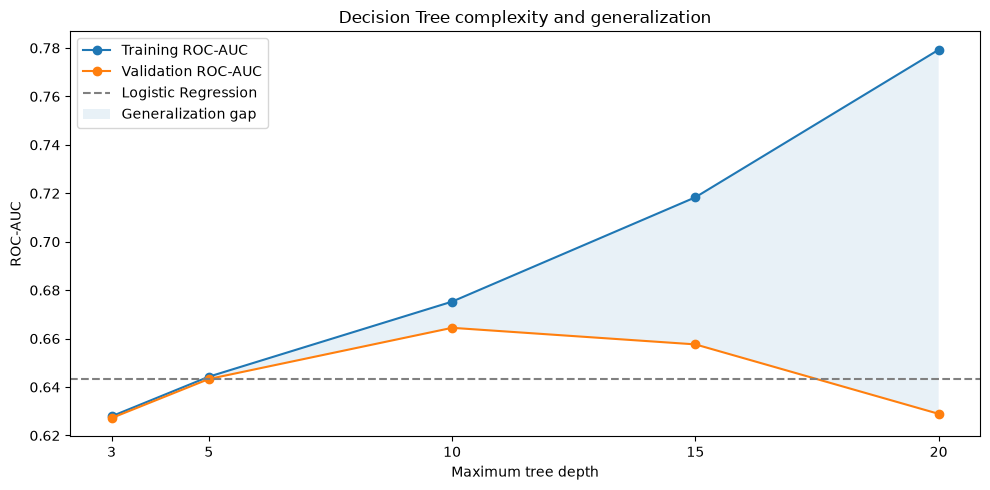

In [144]:
# Visualise the effect of tree complexity on generalization

plt.figure(figsize=(10, 5))

plt.plot(
    depth_comparison["Max depth"],
    depth_comparison["Training ROC-AUC"],
    marker="o",
    label="Training ROC-AUC"
)

plt.plot(
    depth_comparison["Max depth"],
    depth_comparison["Validation ROC-AUC"],
    marker="o",
    label="Validation ROC-AUC"
)

# Logistic Regression reference
plt.axhline(
    model_results["Logistic Regression"]["ROC-AUC"],
    color="gray",
    linestyle="--",
    label="Logistic Regression"
)

# Highlight the generalization gap
plt.fill_between(
    depth_comparison["Max depth"],
    depth_comparison["Training ROC-AUC"],
    depth_comparison["Validation ROC-AUC"],
    alpha=0.1,
    label="Generalization gap"
)

plt.title("Decision Tree complexity and generalization")
plt.xlabel("Maximum tree depth")
plt.ylabel("ROC-AUC")
plt.xticks(depth_comparison["Max depth"])
plt.legend()
plt.tight_layout()
plt.show()

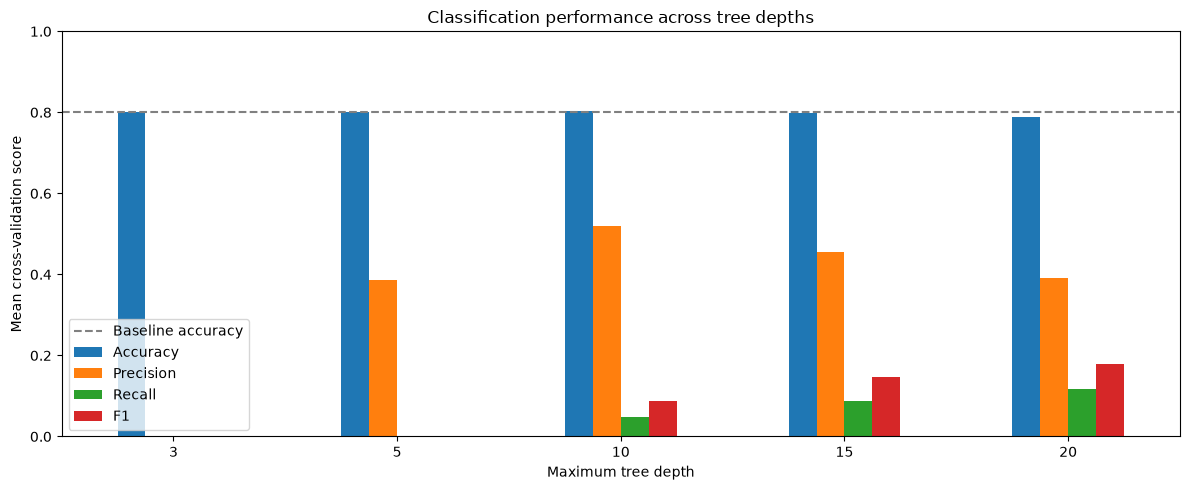

In [145]:
# Compare classification metrics across tree depths

depth_comparison.set_index("Max depth")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

# Add baseline accuracy as a reference
plt.axhline(
    model_results["DummyClassifier"]["Accuracy"],
    color="gray",
    linestyle="--",
    label="Baseline accuracy"
)

plt.title("Classification performance across tree depths")
plt.xlabel("Maximum tree depth")
plt.ylabel("Mean cross-validation score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [146]:
# Store the best Decision Tree from the depth experiment
best_depth_row = depth_comparison.loc[
    depth_comparison["Validation ROC-AUC"].idxmax()
]

best_depth = int(best_depth_row["Max depth"])

model_results[f"Decision Tree (depth {best_depth})"] = {
    "Accuracy": best_depth_row["Accuracy"],
    "Precision": best_depth_row["Precision"],
    "Recall": best_depth_row["Recall"],
    "F1": best_depth_row["F1"],
    "ROC-AUC": best_depth_row["Validation ROC-AUC"],
    "ROC-AUC SD": best_depth_row["ROC-AUC SD"],
    "Training ROC-AUC": best_depth_row["Training ROC-AUC"],
    "Generalization gap": best_depth_row["Generalization gap"]
}

print("Best investigated Decision Tree depth:", best_depth)

Best investigated Decision Tree depth: 10


**Findings – 7.6.1:**

- Increasing maximum tree depth from 3 to 10 improves validation ROC-AUC from 0.6272 to 0.6645, suggesting that shallower trees are limited by insufficient model complexity.
- A maximum depth of 10 achieves the highest validation ROC-AUC among the investigated configurations.
- Beyond depth 10, training ROC-AUC continues to increase while validation ROC-AUC decreases.
- At depth 20, the generalization gap reaches 0.1503, indicating substantial overfitting.
- Although recall and F1-score increase with tree depth, discriminative performance decreases beyond depth 10.
- These results illustrate the bias-variance trade-off discussed in Lecture 6.
- The results motivate further investigation of tree depth and regularization during hyperparameter tuning.

#### 7.6.2 Random Forest complexity and generalization

We investigate whether Random Forest can handle increasing tree complexity more effectively than an individual Decision Tree.

By averaging predictions from multiple trees, Random Forest aims to reduce variance.

We compare different maximum tree depths while keeping the number of trees, feature sampling strategy and remaining hyperparameters unchanged.

The results are compared with the Decision Tree complexity analysis in Section 7.6.1.

In [147]:
# Investigate Random Forest complexity
rf_depth_results = []

for depth in [5, 10, 15, 20]:

    print(f"Evaluating Random Forest depth = {depth}")

    # Reuse the existing depth-10 results
    if depth == 10:
        results = model_results["Random Forest (sqrt)"]

    else:
        rf_depth_model = Pipeline([
            ("preprocessing", preprocessor_unscaled),

            ("classifier", RandomForestClassifier(
                n_estimators=100,
                max_depth=depth,
                criterion="gini",
                max_features="sqrt",
                bootstrap=True,
                random_state=42,
                n_jobs=2
            ))
        ])

        name = f"Random Forest (sqrt, depth {depth})"

        evaluate_model(
            name,
            rf_depth_model,
            X_train_raw,
            y_train
        )

        results = model_results[name]

    rf_depth_results.append({
        "Max depth": depth,
        **results
    })

rf_depth_comparison = pd.DataFrame(rf_depth_results)

display(rf_depth_comparison.round(4))

Evaluating Random Forest depth = 5


,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
"Random Forest (sqrt, depth 5)",0.8021,0.0,0.0,0.0,0.645,0.0016,0.6463,0.0013


Evaluating Random Forest depth = 10
Evaluating Random Forest depth = 15


,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
"Random Forest (sqrt, depth 15)",0.8021,0.7171,0.0004,0.0009,0.6683,0.0015,0.7154,0.0471


Evaluating Random Forest depth = 20


,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
"Random Forest (sqrt, depth 20)",0.8027,0.6009,0.0095,0.0186,0.6726,0.0015,0.7802,0.1076


,Max depth,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
0,5,0.8021,0.0000,0.0000,0.0000,0.6450,0.0016,0.6463,0.0013
1,10,0.8021,0.0000,0.0000,0.0000,0.6579,0.0014,0.6692,0.0112
2,15,0.8021,0.7171,0.0004,0.0009,0.6683,0.0015,0.7154,0.0471
3,20,0.8027,0.6009,0.0095,0.0186,0.6726,0.0015,0.7802,0.1076


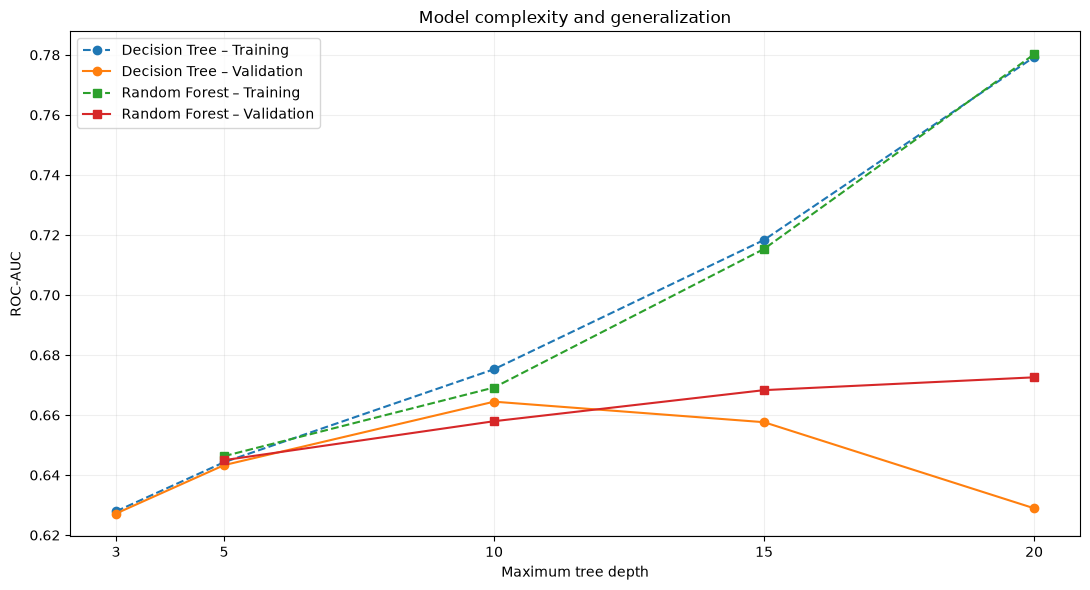

In [148]:
# Compare tree complexity and generalization
plt.figure(figsize=(11, 6))

plt.plot(
    depth_comparison["Max depth"],
    depth_comparison["Training ROC-AUC"],
    marker="o",
    linestyle="--",
    label="Decision Tree – Training"
)

plt.plot(
    depth_comparison["Max depth"],
    depth_comparison["Validation ROC-AUC"],
    marker="o",
    label="Decision Tree – Validation"
)

plt.plot(
    rf_depth_comparison["Max depth"],
    rf_depth_comparison["Training ROC-AUC"],
    marker="s",
    linestyle="--",
    label="Random Forest – Training"
)

plt.plot(
    rf_depth_comparison["Max depth"],
    rf_depth_comparison["ROC-AUC"],
    marker="s",
    label="Random Forest – Validation"
)

plt.title("Model complexity and generalization")
plt.xlabel("Maximum tree depth")
plt.ylabel("ROC-AUC")
plt.xticks([3, 5, 10, 15, 20])
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Findings – 7.6.2:**

- Increasing the maximum tree depth from 5 to 20 improves Random Forest validation ROC-AUC from 0.6450 to 0.6726.
- Unlike the individual Decision Tree, Random Forest continues to improve its validation performance beyond a maximum depth of 10.
- At depth 20, Random Forest achieves a higher validation ROC-AUC (0.6726) than the best individual Decision Tree configuration (0.6645).
- The generalization gap increases with tree depth, reaching 0.1076 at depth 20. However, this remains lower than the corresponding gap of 0.1503 for the individual Decision Tree.
- These results suggest that ensemble learning allows the model to benefit from increased tree complexity while partially reducing the effects of overfitting.
- Despite improved discriminative performance, recall remains very low at the default classification threshold.
- A maximum depth of 20 achieves the highest validation ROC-AUC among the investigated Random Forest depths, although further hyperparameter tuning is required to assess whether this configuration can be improved.

#### 7.6.3 Generalization across models

We compare training and validation ROC-AUC across the initial model configurations.

The difference between training and validation performance provides an indication of potential overfitting. However, a small generalization gap does not necessarily imply strong predictive performance, as insufficient model complexity may also result in a small gap.

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Model,,,,,,,,
DummyClassifier,0.8021,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000,0.0000
Logistic Regression,0.8020,0.4383,0.0012,0.0025,0.6435,0.0008,0.6450,0.0015
Logistic Regression (balanced),0.6033,0.2734,0.6057,0.3768,0.6437,0.0007,0.6452,0.0016
Decision Tree,0.8021,0.3851,0.0001,0.0003,0.6433,0.0015,0.6443,0.0010
Decision Tree (balanced),0.6122,0.2754,0.5874,0.3749,0.6428,0.0016,0.6437,0.0010
Random Forest (sqrt),0.8021,0.0000,0.0000,0.0000,0.6579,0.0014,0.6692,0.0112
"Random Forest (balanced, sqrt)",0.5893,0.2712,0.6371,0.3805,0.6570,0.0011,0.6674,0.0104


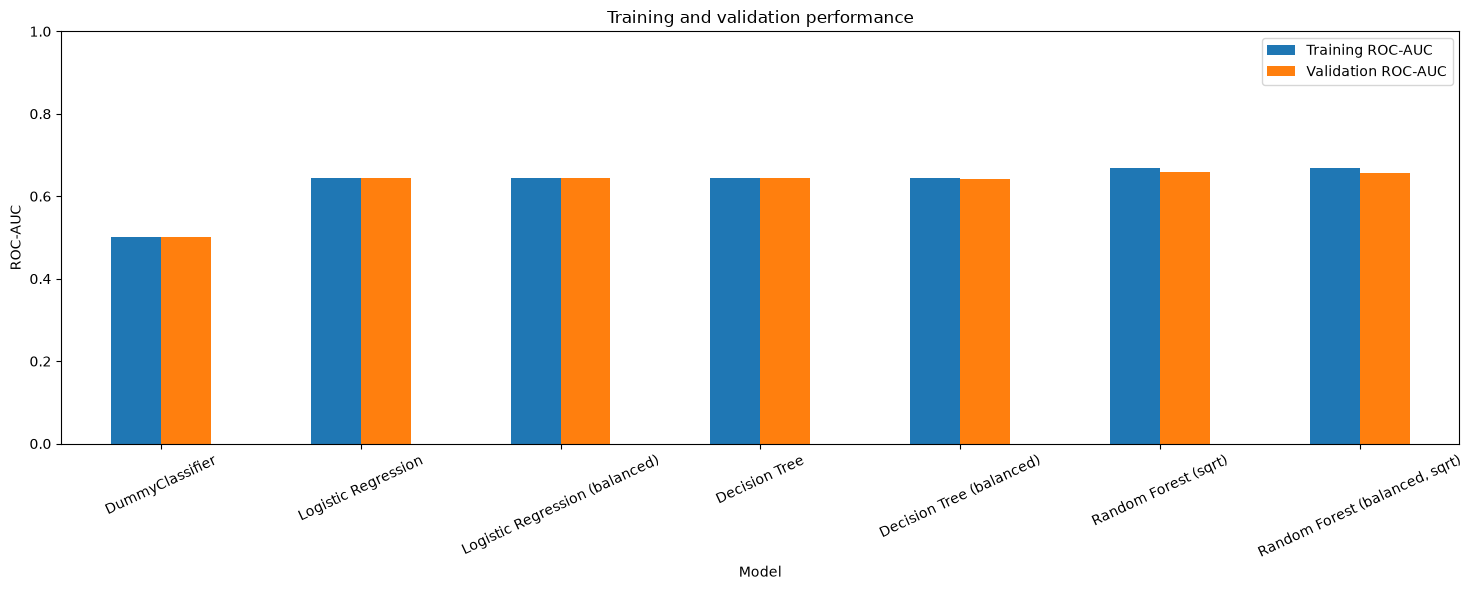

In [149]:
# Compare initial model configurations
initial_models = [
    "DummyClassifier",
    "Logistic Regression",
    "Logistic Regression (balanced)",
    "Decision Tree",
    "Decision Tree (balanced)",
    "Random Forest (sqrt)",
    "Random Forest (balanced, sqrt)"
]

generalization_comparison = compare_models(
    initial_models
)

generalization_comparison[
    ["Training ROC-AUC", "ROC-AUC"]
].rename(
    columns={"ROC-AUC": "Validation ROC-AUC"}
).plot(
    kind="bar",
    figsize=(15, 6)
)

plt.title("Training and validation performance")
plt.ylabel("ROC-AUC")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.legend()
plt.tight_layout()
plt.show()

**Findings – 7.6:**

- The initial Logistic Regression and Decision Tree configurations exhibit very small generalization gaps, providing little indication of overfitting under the current cross-validation strategy.
- However, a small generalization gap does not necessarily indicate strong predictive performance, as insufficient model complexity may also limit the ability to capture relevant patterns.
- The Decision Tree complexity analysis demonstrates a clear trade-off between underfitting and overfitting, with validation performance peaking at a maximum depth of 10.
- Random Forest benefits from deeper trees across the investigated range, although its generalization gap also increases with model complexity.
- The results suggest that ensemble learning can partially mitigate the effects of increasing tree complexity.
- These findings motivate the use of regularization and controlled hyperparameter tuning to improve predictive performance and generalization.

The following section uses these findings to guide hyperparameter tuning without accessing the holdout test set.

### 7.7 Hyperparameter Tuning

**What we do:** We investigate alternative hyperparameter configurations for Logistic Regression, Decision Tree and Random Forest.

**Why:** The preceding analyses demonstrated that model complexity and class weighting influence predictive performance.

We use the findings from Section 7.6 to guide the selection of hyperparameter configurations and avoid unnecessary computational cost.

Validation ROC-AUC remains the primary model selection metric, while accuracy, precision, recall, F1-score and generalization gaps provide complementary information.

All hyperparameter tuning is performed using 3-fold stratified cross-validation within the training set.

**Hyperparameter tuning strategy**

We use GridSearchCV to systematically evaluate combinations of hyperparameters for each model type.

The search spaces are informed by the findings from our initial modelling and model generalization analyses. Previously investigated configurations are retained as reference points.

All configurations are evaluated using the same three stratified cross-validation folds and evaluation metrics.

The best configuration is selected based on mean validation ROC-AUC. Training ROC-AUC and the generalization gap are also recorded to investigate potential overfitting.

The holdout test set remains unused throughout hyperparameter tuning.

In [156]:
# Common function for hyperparameter tuning
def tune_model(name, model, param_grid):

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring=scoring,
        refit=False,
        cv=cv,
        return_train_score=True,
        n_jobs=1,
        verbose=2,
        error_score="raise"
    )

    # Perform hyperparameter tuning on training data only
    grid_search.fit(X_train_raw, y_train)

    cv_results = pd.DataFrame(grid_search.cv_results_)

    # Create a comparison table
    results = cv_results[[
        "params",
        "mean_test_accuracy",
        "mean_test_precision",
        "mean_test_recall",
        "mean_test_f1",
        "mean_test_roc_auc",
        "std_test_roc_auc",
        "mean_train_roc_auc"
    ]].copy()

    results = results.rename(columns={
        "params": "Parameters",
        "mean_test_accuracy": "Accuracy",
        "mean_test_precision": "Precision",
        "mean_test_recall": "Recall",
        "mean_test_f1": "F1",
        "mean_test_roc_auc": "ROC-AUC",
        "std_test_roc_auc": "ROC-AUC SD",
        "mean_train_roc_auc": "Training ROC-AUC"
    })

    # Calculate generalization gap
    results["Generalization gap"] = (
        results["Training ROC-AUC"]
        - results["ROC-AUC"]
    )

    # Rank configurations by validation ROC-AUC
    results = results.sort_values(
        "ROC-AUC",
        ascending=False
    ).reset_index(drop=True)

    # Identify the best configuration
    best_result = results.iloc[0]

    best_params = best_result["Parameters"]

    # Store the best configuration in model_results
    model_results[name] = (
        best_result.drop("Parameters").to_dict()
    )

    print("\nBest parameters:")
    print(best_params)

    print("\nBest validation ROC-AUC:")
    print(round(best_result["ROC-AUC"], 4))

    display(results.round(4))

    return grid_search, results, best_params

#### 7.7.1 Logistic Regression hyperparameter tuning

**What we do:** We investigate the effect of regularization strength and class weighting on Logistic Regression performance.

**Why:** The initial Logistic Regression models exhibit small generalization gaps but relatively limited discriminative performance.

Logistic Regression uses L2 regularization to penalize large coefficients and control model complexity.

The hyperparameter C represents the inverse of regularization strength:

- Smaller C values apply stronger regularization.
- Larger C values apply weaker regularization.

We investigate whether alternative regularization strengths improve predictive performance and whether their effect depends on the use of balanced class weights.

All configurations are evaluated using the existing preprocessing pipeline and cross-validation strategy.

In [157]:
# Logistic Regression hyperparameter search space
lr_param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 10],
    "classifier__class_weight": [None, "balanced"]
}

In [158]:
# Tune Logistic Regression
lr_grid_search, lr_tuning_results, lr_best_params = tune_model(
    name="Logistic Regression (tuned)",
    model=logistic_model,
    param_grid=lr_param_grid
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END .classifier__C=0.001, classifier__class_weight=None; total time=   0.7s
[CV] END .classifier__C=0.001, classifier__class_weight=None; total time=   0.6s
[CV] END .classifier__C=0.001, classifier__class_weight=None; total time=   0.6s
[CV] END classifier__C=0.001, classifier__class_weight=balanced; total time=   0.7s
[CV] END classifier__C=0.001, classifier__class_weight=balanced; total time=   0.7s
[CV] END classifier__C=0.001, classifier__class_weight=balanced; total time=   0.7s
[CV] END ..classifier__C=0.01, classifier__class_weight=None; total time=   0.9s
[CV] END ..classifier__C=0.01, classifier__class_weight=None; total time=   0.9s
[CV] END ..classifier__C=0.01, classifier__class_weight=None; total time=   0.9s
[CV] END classifier__C=0.01, classifier__class_weight=balanced; total time=   1.1s
[CV] END classifier__C=0.01, classifier__class_weight=balanced; total time=   1.2s
[CV] END classifier__C=0.01, classif

,Parameters,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
0,"{'classifier__C': 0.1, 'classifier__class_weig...",0.6035,0.2735,0.6057,0.3768,0.6437,0.0007,0.6452,0.0015
1,"{'classifier__C': 10, 'classifier__class_weigh...",0.6033,0.2734,0.6055,0.3767,0.6436,0.0008,0.6452,0.0016
2,"{'classifier__C': 10, 'classifier__class_weigh...",0.8020,0.4456,0.0011,0.0022,0.6435,0.0007,0.6450,0.0015
3,"{'classifier__C': 0.01, 'classifier__class_wei...",0.6040,0.2737,0.6049,0.3769,0.6435,0.0009,0.6446,0.0011
4,"{'classifier__C': 0.1, 'classifier__class_weig...",0.8020,0.4537,0.0011,0.0023,0.6435,0.0007,0.6449,0.0014
5,"{'classifier__C': 0.01, 'classifier__class_wei...",0.8020,0.4709,0.0004,0.0007,0.6432,0.0009,0.6442,0.0010
6,"{'classifier__C': 0.001, 'classifier__class_we...",0.6013,0.2721,0.6058,0.3756,0.6404,0.0011,0.6409,0.0005
7,"{'classifier__C': 0.001, 'classifier__class_we...",0.8021,0.0000,0.0000,0.0000,0.6393,0.0011,0.6397,0.0004


In [159]:
# Include the existing C=1 configurations
lr_reference_results = pd.DataFrame([
    {
        "Parameters": {
            "classifier__C": 1.0,
            "classifier__class_weight": None
        },
        **model_results["Logistic Regression"]
    },
    {
        "Parameters": {
            "classifier__C": 1.0,
            "classifier__class_weight": "balanced"
        },
        **model_results["Logistic Regression (balanced)"]
    }
])

# Compare all investigated configurations
lr_all_results = pd.concat(
    [lr_reference_results, lr_tuning_results],
    ignore_index=True
).sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(lr_all_results.round(4))

# Select the best overall Logistic Regression configuration
lr_best_params = lr_all_results.iloc[0]["Parameters"]

model_results["Logistic Regression (tuned)"] = (
    lr_all_results.iloc[0]
    .drop("Parameters")
    .to_dict()
)

print("Selected parameters:", lr_best_params)

,Parameters,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
0,"{'classifier__C': 0.1, 'classifier__class_weig...",0.6035,0.2735,0.6057,0.3768,0.6437,0.0007,0.6452,0.0015
1,"{'classifier__C': 1.0, 'classifier__class_weig...",0.6033,0.2734,0.6057,0.3768,0.6437,0.0007,0.6452,0.0016
2,"{'classifier__C': 10, 'classifier__class_weigh...",0.6033,0.2734,0.6055,0.3767,0.6436,0.0008,0.6452,0.0016
3,"{'classifier__C': 10, 'classifier__class_weigh...",0.8020,0.4456,0.0011,0.0022,0.6435,0.0007,0.6450,0.0015
4,"{'classifier__C': 1.0, 'classifier__class_weig...",0.8020,0.4383,0.0012,0.0025,0.6435,0.0008,0.6450,0.0015
5,"{'classifier__C': 0.01, 'classifier__class_wei...",0.6040,0.2737,0.6049,0.3769,0.6435,0.0009,0.6446,0.0011
6,"{'classifier__C': 0.1, 'classifier__class_weig...",0.8020,0.4537,0.0011,0.0023,0.6435,0.0007,0.6449,0.0014
7,"{'classifier__C': 0.01, 'classifier__class_wei...",0.8020,0.4709,0.0004,0.0007,0.6432,0.0009,0.6442,0.0010
8,"{'classifier__C': 0.001, 'classifier__class_we...",0.6013,0.2721,0.6058,0.3756,0.6404,0.0011,0.6409,0.0005
9,"{'classifier__C': 0.001, 'classifier__class_we...",0.8021,0.0000,0.0000,0.0000,0.6393,0.0011,0.6397,0.0004


Selected parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}


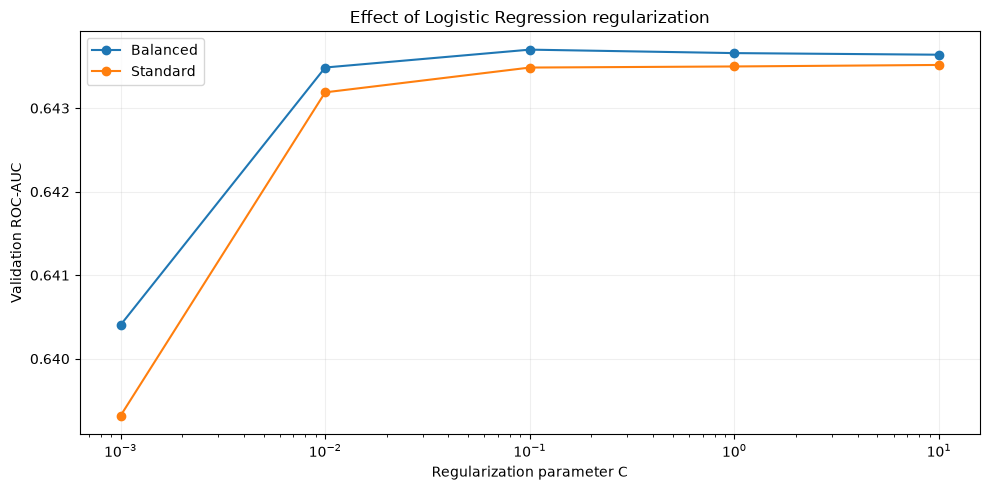

In [160]:
# Extract hyperparameter values for visualization
lr_plot = lr_all_results.copy()

lr_plot["C"] = lr_plot["Parameters"].apply(
    lambda p: p["classifier__C"]
)

lr_plot["Class weight"] = lr_plot["Parameters"].apply(
    lambda p: (
        "Balanced"
        if p["classifier__class_weight"] == "balanced"
        else "Standard"
    )
)

plt.figure(figsize=(10, 5))

for weight, group in lr_plot.groupby("Class weight"):

    group = group.sort_values("C")

    plt.plot(
        group["C"],
        group["ROC-AUC"],
        marker="o",
        label=weight
    )

plt.xscale("log")
plt.xlabel("Regularization parameter C")
plt.ylabel("Validation ROC-AUC")
plt.title("Effect of Logistic Regression regularization")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Findings – 7.7.1:**

- The highest mean validation ROC-AUC is achieved using C = 0.1 and balanced class weights.
- However, the selected configuration achieves a validation ROC-AUC of 0.6437, which is practically identical to the initial balanced Logistic Regression model.
- Stronger regularization (C = 0.001) reduces validation performance, suggesting that excessive regularization may limit the model's ability to capture relevant relationships.
- Generalization gaps remain small across all investigated configurations.
- Balanced class weighting continues to improve recall and F1-score at the default classification threshold, without substantially improving discriminative performance.
- Overall, hyperparameter tuning provides no meaningful improvement in Logistic Regression performance within the investigated search space.

#### 7.7.2 Decision Tree hyperparameter tuning

**What we do:** We investigate combinations of maximum tree depth, minimum samples per leaf and class weighting.

**Why:** The model generalization analysis in Section 7.6.1 demonstrated that increasing tree depth initially improves validation performance but eventually leads to overfitting.

A maximum depth of 10 achieved the highest validation ROC-AUC among the previously investigated configurations.

We introduce `min_samples_leaf` as an additional regularization parameter. This parameter controls the minimum number of training observations required in a terminal node.

Increasing the minimum leaf size may prevent the model from creating highly specific groups based on relatively few observations.

We investigate whether this additional constraint allows more complex trees to capture relevant relationships while maintaining generalization performance.

In [161]:
# Decision Tree hyperparameter search space
dt_param_grid = {
    "classifier__max_depth": [8, 10, 15],
    "classifier__min_samples_leaf": [50, 200],
    "classifier__class_weight": [None, "balanced"]
}

In [162]:
# Tune Decision Tree
dt_grid_search, dt_tuning_results, dt_best_params = tune_model(
    name="Decision Tree (tuned)",
    model=tree_model,
    param_grid=dt_param_grid
)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
[CV] END classifier__class_weight=None, classifier__max_depth=8, classifier__min_samples_leaf=50; total time=   2.0s
[CV] END classifier__class_weight=None, classifier__max_depth=8, classifier__min_samples_leaf=50; total time=   2.0s
[CV] END classifier__class_weight=None, classifier__max_depth=8, classifier__min_samples_leaf=50; total time=   1.9s
[CV] END classifier__class_weight=None, classifier__max_depth=8, classifier__min_samples_leaf=200; total time=   2.0s
[CV] END classifier__class_weight=None, classifier__max_depth=8, classifier__min_samples_leaf=200; total time=   2.0s
[CV] END classifier__class_weight=None, classifier__max_depth=8, classifier__min_samples_leaf=200; total time=   1.9s
[CV] END classifier__class_weight=None, classifier__max_depth=10, classifier__min_samples_leaf=50; total time=   2.9s
[CV] END classifier__class_weight=None, classifier__max_depth=10, classifier__min_samples_leaf=50; total time=   3.1

,Parameters,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
0,"{'classifier__class_weight': None, 'classifier...",0.8030,0.5236,0.0545,0.0987,0.6716,0.0013,0.6927,0.0211
1,"{'classifier__class_weight': 'balanced', 'clas...",0.6229,0.2893,0.6212,0.3947,0.6711,0.0015,0.6940,0.0229
2,"{'classifier__class_weight': None, 'classifier...",0.8025,0.5071,0.0764,0.1328,0.6688,0.0019,0.7049,0.0361
3,"{'classifier__class_weight': 'balanced', 'clas...",0.6186,0.2873,0.6258,0.3938,0.6680,0.0012,0.7085,0.0405
4,"{'classifier__class_weight': None, 'classifier...",0.8030,0.5306,0.0428,0.0790,0.6654,0.0007,0.6733,0.0079
5,"{'classifier__class_weight': None, 'classifier...",0.8031,0.5249,0.0538,0.0975,0.6647,0.0009,0.6750,0.0103
6,"{'classifier__class_weight': 'balanced', 'clas...",0.6227,0.2870,0.6104,0.3904,0.6646,0.0018,0.6758,0.0112
7,"{'classifier__class_weight': 'balanced', 'clas...",0.6193,0.2857,0.6152,0.3902,0.6646,0.0019,0.6734,0.0089
8,"{'classifier__class_weight': None, 'classifier...",0.8030,0.5383,0.0328,0.0619,0.6590,0.0009,0.6625,0.0035
9,"{'classifier__class_weight': None, 'classifier...",0.8029,0.5299,0.0389,0.0725,0.6586,0.0012,0.6627,0.0041


In [163]:
# Reuse the previous Decision Tree depth experiment
dt_reference_results = depth_comparison.rename(
    columns={"Validation ROC-AUC": "ROC-AUC"}
).copy()

dt_reference_results["Parameters"] = (
    dt_reference_results["Max depth"].apply(
        lambda depth: {
            "classifier__max_depth": int(depth),
            "classifier__min_samples_leaf": 1,
            "classifier__class_weight": None
        }
    )
)

dt_reference_results = dt_reference_results.drop(
    columns="Max depth"
)

# Include the initial balanced Decision Tree
dt_balanced_reference = pd.DataFrame([
    {
        "Parameters": {
            "classifier__max_depth": 5,
            "classifier__min_samples_leaf": 1,
            "classifier__class_weight": "balanced"
        },
        **model_results["Decision Tree (balanced)"]
    }
])

# Compare all investigated configurations
dt_all_results = pd.concat(
    [
        dt_reference_results,
        dt_balanced_reference,
        dt_tuning_results
    ],
    ignore_index=True
).sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(dt_all_results.round(4))

# Select the best overall Decision Tree configuration
dt_best_params = dt_all_results.iloc[0]["Parameters"]

model_results["Decision Tree (tuned)"] = (
    dt_all_results.iloc[0]
    .drop("Parameters")
    .to_dict()
)

print("Selected parameters:", dt_best_params)

,Accuracy,Precision,Recall,F1,Training ROC-AUC,ROC-AUC,ROC-AUC SD,Generalization gap,Parameters
0,0.8030,0.5236,0.0545,0.0987,0.6927,0.6716,0.0013,0.0211,"{'classifier__class_weight': None, 'classifier..."
1,0.6229,0.2893,0.6212,0.3947,0.6940,0.6711,0.0015,0.0229,"{'classifier__class_weight': 'balanced', 'clas..."
2,0.8025,0.5071,0.0764,0.1328,0.7049,0.6688,0.0019,0.0361,"{'classifier__class_weight': None, 'classifier..."
3,0.6186,0.2873,0.6258,0.3938,0.7085,0.6680,0.0012,0.0405,"{'classifier__class_weight': 'balanced', 'clas..."
4,0.8030,0.5306,0.0428,0.0790,0.6733,0.6654,0.0007,0.0079,"{'classifier__class_weight': None, 'classifier..."
5,0.8031,0.5249,0.0538,0.0975,0.6750,0.6647,0.0009,0.0103,"{'classifier__class_weight': None, 'classifier..."
6,0.6227,0.2870,0.6104,0.3904,0.6758,0.6646,0.0018,0.0112,"{'classifier__class_weight': 'balanced', 'clas..."
7,0.6193,0.2857,0.6152,0.3902,0.6734,0.6646,0.0019,0.0089,"{'classifier__class_weight': 'balanced', 'clas..."
8,0.8027,0.5187,0.0484,0.0885,0.6753,0.6645,0.0009,0.0108,"{'classifier__max_depth': 10, 'classifier__min..."
9,0.8030,0.5383,0.0328,0.0619,0.6625,0.6590,0.0009,0.0035,"{'classifier__class_weight': None, 'classifier..."


Selected parameters: {'classifier__class_weight': None, 'classifier__max_depth': 15, 'classifier__min_samples_leaf': 200}


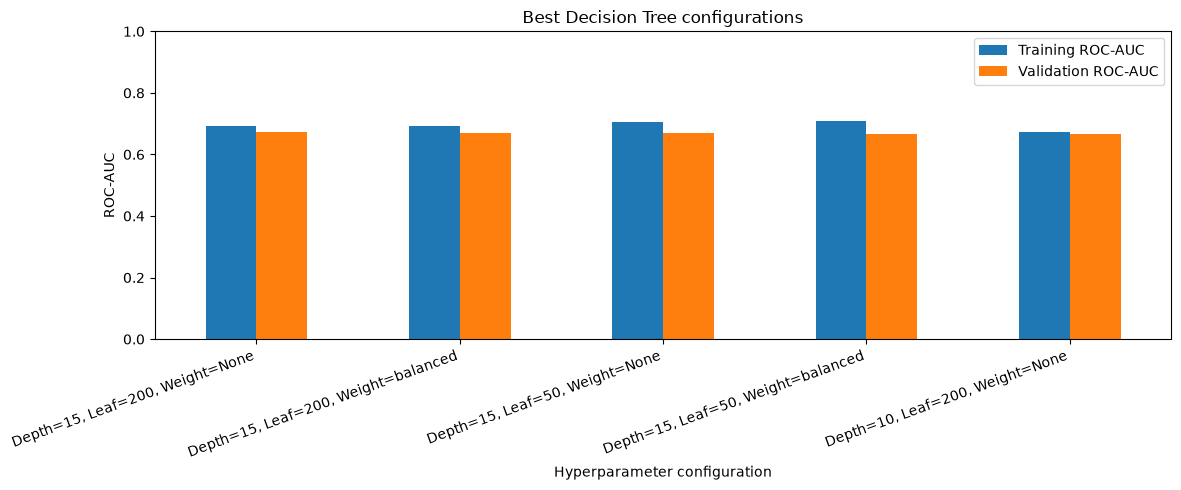

In [164]:
# Visualize the five best Decision Tree configurations
dt_top5 = dt_all_results.head(5).copy()

dt_top5["Configuration"] = (
    dt_top5["Parameters"].apply(
        lambda p: (
            f"Depth={p['classifier__max_depth']}, "
            f"Leaf={p['classifier__min_samples_leaf']}, "
            f"Weight={p['classifier__class_weight']}"
        )
    )
)

dt_top5.set_index("Configuration")[
    ["Training ROC-AUC", "ROC-AUC"]
].rename(
    columns={"ROC-AUC": "Validation ROC-AUC"}
).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Best Decision Tree configurations")
plt.ylabel("ROC-AUC")
plt.xlabel("Hyperparameter configuration")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

**Findings – 7.7.2:**

- The best Decision Tree configuration uses a maximum depth of 15, a minimum leaf size of 200 and no class weighting.
- Validation ROC-AUC improves from 0.6645 for the previously selected depth-10 model to 0.6716.
- At a maximum depth of 15, increasing min_samples_leaf from 1 to 200 improves validation ROC-AUC from 0.6576 to 0.6716 while reducing the generalization gap from 0.0607 to 0.0211.
- These results demonstrate how additional regularization can allow deeper trees to capture more complex relationships while reducing overfitting.
- The best balanced configuration achieves a similar validation ROC-AUC of 0.6711, together with a recall of 0.6212 and an F1-score of 0.3947.
- The selected unweighted configuration achieves the highest validation ROC-AUC, although recall remains limited at the default classification threshold.
- Overall, hyperparameter tuning improves the predictive performance of the Decision Tree and illustrates the importance of considering interactions between hyperparameters.

#### 7.7.3 Random Forest hyperparameter tuning

##### 7.7.3.1 Effect of feature sampling
The initial Random Forest configurations use `max_features="sqrt"`.

After One-Hot Encoding, approximately 306 of the 312 input features represent airport categories, while only six are numerical predictors.

Consequently, the numerical predictors may be underrepresented in the randomly selected feature subsets considered at each split.

We investigate this potential limitation by setting `max_features=None`, allowing all available features to be considered at each split.

All other hyperparameters remain unchanged to isolate the effect of feature sampling.

In [150]:
# Random Forest with all features
forest_all_features = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        criterion="gini",
        max_features=None,
        bootstrap=True,
        random_state=42,
        n_jobs=2
    ))
])

forest_all_features_scores = evaluate_model(
    "Random Forest (all features)",
    forest_all_features,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Random Forest (all features),0.8039,0.5699,0.0387,0.0724,0.6752,0.0014,0.6886,0.0135


In [151]:
# Balanced Random Forest with all features
forest_balanced_all_features = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        criterion="gini",
        max_features=None,
        bootstrap=True,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

forest_balanced_all_features_scores = evaluate_model(
    "Random Forest (balanced, all features)",
    forest_balanced_all_features,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
"Random Forest (balanced, all features)",0.6258,0.2919,0.6245,0.3978,0.6748,0.0015,0.6908,0.016


In [152]:
# Compare the effect of feature sampling
feature_sampling_comparison = compare_models([
    "Random Forest (sqrt)",
    "Random Forest (all features)",
    "Random Forest (balanced, sqrt)",
    "Random Forest (balanced, all features)"
])

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Model,,,,,,,,
Random Forest (sqrt),0.8021,0.0000,0.0000,0.0000,0.6579,0.0014,0.6692,0.0112
Random Forest (all features),0.8039,0.5699,0.0387,0.0724,0.6752,0.0014,0.6886,0.0135
"Random Forest (balanced, sqrt)",0.5893,0.2712,0.6371,0.3805,0.6570,0.0011,0.6674,0.0104
"Random Forest (balanced, all features)",0.6258,0.2919,0.6245,0.3978,0.6748,0.0015,0.6908,0.0160


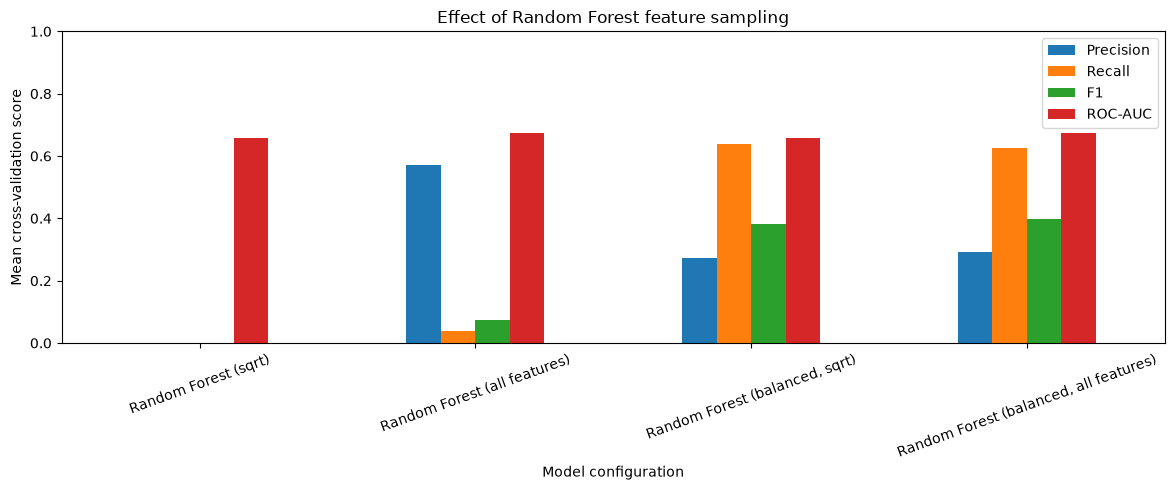

In [153]:
feature_sampling_comparison[
    ["Precision", "Recall", "F1", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Effect of Random Forest feature sampling")
plt.ylabel("Mean cross-validation score")
plt.xlabel("Model configuration")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

##### Findings 7.7.3.1
- Removing the feature sampling restriction increases validation ROC-AUC from 0.6579 to 0.6752 for the standard Random Forest and from 0.6570 to 0.6748 for the balanced Random Forest.
- Both configurations therefore benefit from considering all features at each split under the investigated settings.
- The balanced configuration improves its F1-score from 0.3805 to 0.3978, while maintaining a recall of 0.6245.
- The generalization gaps increase slightly, indicating a trade-off between improved predictive performance and model complexity.
- These findings support the hypothesis that the extensive One-Hot Encoding may make the default square-root feature sampling strategy less suitable for this dataset.
- However, the experiment does not establish whether the improvement is specifically attributable to the numerical predictors.
- The results highlight the importance of considering interactions between preprocessing and hyperparameter choices.

##### 7.7.3.2 Combined Random Forest hyperparameter tuning

**What we do:** We investigate selected combinations of maximum tree depth, minimum leaf size, feature sampling and class weighting.

**Why:** Our previous analyses identified several opportunities for improving Random Forest performance:

- Section 7.6.2 demonstrated that deeper trees improve validation ROC-AUC, although the generalization gap increases.
- Section 7.7.2 demonstrated that increasing the minimum leaf size can reduce overfitting and improve Decision Tree performance.
- Section 7.7.3.1 demonstrated that allowing all features to be considered at each split improves Random Forest performance.

We combine these findings to investigate whether deeper trees, additional regularization and greater access to informative predictors can improve predictive performance.

Due to the computational cost of Random Forest, we use a targeted hyperparameter search rather than evaluating every possible combination.

The number of trees is fixed at 100, and all configurations are evaluated using the existing preprocessing pipeline and three-fold stratified cross-validation.

The best configuration is selected based on validation ROC-AUC.

In [165]:
# Targeted Random Forest hyperparameter search space

rf_param_grid = [

    # Investigate intermediate feature sampling
    {
        "classifier__max_depth": [15],
        "classifier__min_samples_leaf": [200],
        "classifier__max_features": [0.25],
        "classifier__class_weight": [None, "balanced"]
    },

    # Investigate all features with regularization
    {
        "classifier__max_depth": [15],
        "classifier__min_samples_leaf": [200],
        "classifier__max_features": [None],
        "classifier__class_weight": [None, "balanced"]
    },

    # Investigate deeper trees with regularization
    {
        "classifier__max_depth": [20],
        "classifier__min_samples_leaf": [200],
        "classifier__max_features": [None],
        "classifier__class_weight": [None, "balanced"]
    },

    # Investigate weaker leaf-size regularization
    {
        "classifier__max_depth": [15],
        "classifier__min_samples_leaf": [50],
        "classifier__max_features": [None],
        "classifier__class_weight": [None, "balanced"]
    }
]

In [166]:
# Tune Random Forest
rf_grid_search, rf_tuning_results, rf_best_params = tune_model(
    name="Random Forest (tuned)",
    model=forest_model,
    param_grid=rf_param_grid
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END classifier__class_weight=None, classifier__max_depth=15, classifier__max_features=0.25, classifier__min_samples_leaf=200; total time=  50.2s
[CV] END classifier__class_weight=None, classifier__max_depth=15, classifier__max_features=0.25, classifier__min_samples_leaf=200; total time=  51.9s
[CV] END classifier__class_weight=None, classifier__max_depth=15, classifier__max_features=0.25, classifier__min_samples_leaf=200; total time=  53.3s
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifier__max_features=0.25, classifier__min_samples_leaf=200; total time=  52.3s
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifier__max_features=0.25, classifier__min_samples_leaf=200; total time=  52.4s
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifier__max_features=0.25, classifier__min_samples_leaf=200; total time=  52.4s
[CV] END classifier__class_w

,Parameters,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
0,"{'classifier__class_weight': None, 'classifier...",0.8043,0.5587,0.0538,0.0982,0.6878,0.0013,0.7209,0.0332
1,"{'classifier__class_weight': 'balanced', 'clas...",0.6413,0.3023,0.6208,0.4066,0.6867,0.0015,0.7238,0.0370
2,"{'classifier__class_weight': None, 'classifier...",0.8035,0.5525,0.0371,0.0695,0.6844,0.0014,0.7071,0.0227
3,"{'classifier__class_weight': None, 'classifier...",0.8034,0.5532,0.0352,0.0661,0.6828,0.0013,0.7005,0.0178
4,"{'classifier__class_weight': 'balanced', 'clas...",0.6341,0.2977,0.6244,0.4032,0.6823,0.0014,0.7029,0.0206
5,"{'classifier__class_weight': 'balanced', 'clas...",0.6291,0.2952,0.6296,0.4019,0.6812,0.0014,0.6986,0.0174
6,"{'classifier__class_weight': None, 'classifier...",0.8021,0.6486,0.0010,0.0021,0.6783,0.0014,0.6874,0.0091
7,"{'classifier__class_weight': 'balanced', 'clas...",0.6223,0.2911,0.6329,0.3988,0.6773,0.0017,0.6862,0.0089


In [167]:
# Reuse Random Forest depth experiment
rf_reference_results = rf_depth_comparison.copy()

# Add hyperparameter configurations
rf_reference_results["Parameters"] = (
    rf_reference_results["Max depth"].apply(
        lambda depth: {
            "classifier__max_depth": int(depth),
            "classifier__min_samples_leaf": 1,
            "classifier__max_features": "sqrt",
            "classifier__class_weight": None
        }
    )
)

rf_reference_results = rf_reference_results.drop(
    columns="Max depth"
)

# Include previous class weighting and feature sampling experiments
rf_additional_references = pd.DataFrame([

    {
        "Parameters": {
            "classifier__max_depth": 10,
            "classifier__min_samples_leaf": 1,
            "classifier__max_features": "sqrt",
            "classifier__class_weight": "balanced"
        },
        **model_results["Random Forest (balanced, sqrt)"]
    },

    {
        "Parameters": {
            "classifier__max_depth": 10,
            "classifier__min_samples_leaf": 1,
            "classifier__max_features": None,
            "classifier__class_weight": None
        },
        **model_results["Random Forest (all features)"]
    },

    {
        "Parameters": {
            "classifier__max_depth": 10,
            "classifier__min_samples_leaf": 1,
            "classifier__max_features": None,
            "classifier__class_weight": "balanced"
        },
        **model_results["Random Forest (balanced, all features)"]
    }

])

# Compare all previously and newly investigated configurations
rf_all_results = pd.concat(
    [
        rf_reference_results,
        rf_additional_references,
        rf_tuning_results
    ],
    ignore_index=True
).sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(rf_all_results.round(4))

# Select the best overall Random Forest configuration
rf_best_params = rf_all_results.iloc[0]["Parameters"]

model_results["Random Forest (tuned)"] = (
    rf_all_results.iloc[0]
    .drop("Parameters")
    .to_dict()
)

print("Selected parameters:")
print(rf_best_params)

print("\nBest validation ROC-AUC:")
print(round(rf_all_results.iloc[0]["ROC-AUC"], 4))

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap,Parameters
0,0.8043,0.5587,0.0538,0.0982,0.6878,0.0013,0.7209,0.0332,"{'classifier__class_weight': None, 'classifier..."
1,0.6413,0.3023,0.6208,0.4066,0.6867,0.0015,0.7238,0.0370,"{'classifier__class_weight': 'balanced', 'clas..."
2,0.8035,0.5525,0.0371,0.0695,0.6844,0.0014,0.7071,0.0227,"{'classifier__class_weight': None, 'classifier..."
3,0.8034,0.5532,0.0352,0.0661,0.6828,0.0013,0.7005,0.0178,"{'classifier__class_weight': None, 'classifier..."
4,0.6341,0.2977,0.6244,0.4032,0.6823,0.0014,0.7029,0.0206,"{'classifier__class_weight': 'balanced', 'clas..."
5,0.6291,0.2952,0.6296,0.4019,0.6812,0.0014,0.6986,0.0174,"{'classifier__class_weight': 'balanced', 'clas..."
6,0.8021,0.6486,0.0010,0.0021,0.6783,0.0014,0.6874,0.0091,"{'classifier__class_weight': None, 'classifier..."
7,0.6223,0.2911,0.6329,0.3988,0.6773,0.0017,0.6862,0.0089,"{'classifier__class_weight': 'balanced', 'clas..."
8,0.8039,0.5699,0.0387,0.0724,0.6752,0.0014,0.6886,0.0135,"{'classifier__max_depth': 10, 'classifier__min..."
9,0.6258,0.2919,0.6245,0.3978,0.6748,0.0015,0.6908,0.0160,"{'classifier__max_depth': 10, 'classifier__min..."


Selected parameters:
{'classifier__class_weight': None, 'classifier__max_depth': 15, 'classifier__max_features': None, 'classifier__min_samples_leaf': 50}

Best validation ROC-AUC:
0.6878


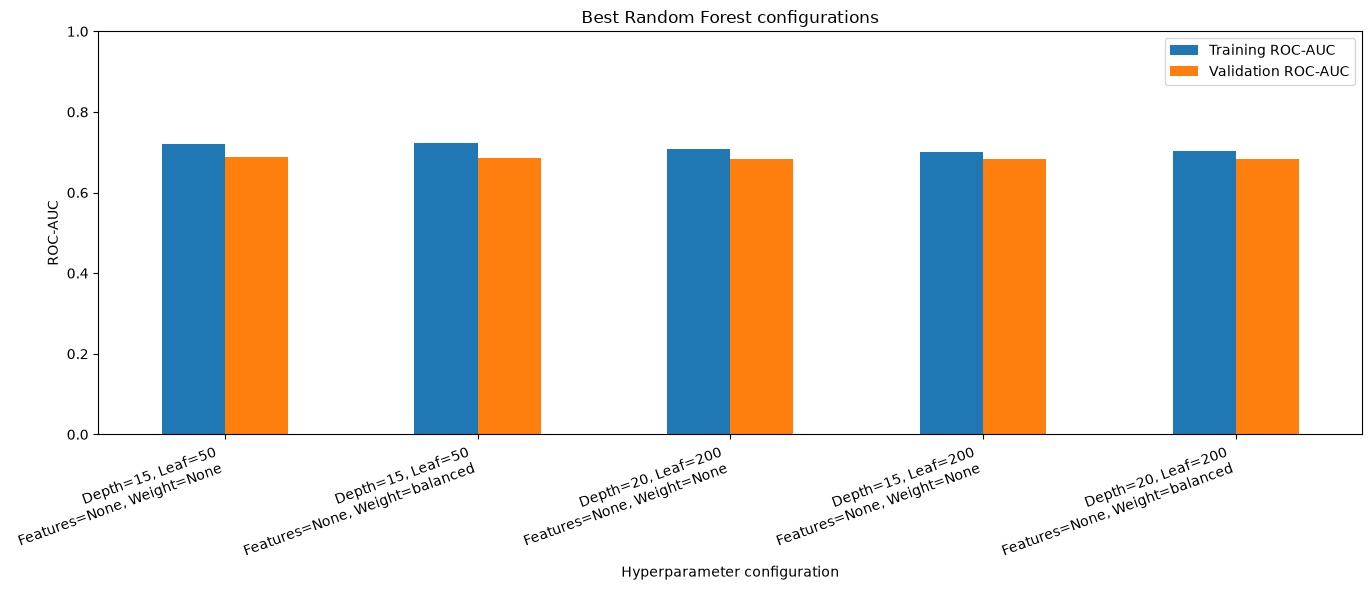

In [168]:
# Visualize the five best Random Forest configurations
rf_top5 = rf_all_results.head(5).copy()

rf_top5["Configuration"] = (
    rf_top5["Parameters"].apply(
        lambda p: (
            f"Depth={p['classifier__max_depth']}, "
            f"Leaf={p['classifier__min_samples_leaf']}\n"
            f"Features={p['classifier__max_features']}, "
            f"Weight={p['classifier__class_weight']}"
        )
    )
)

rf_top5.set_index("Configuration")[
    ["Training ROC-AUC", "ROC-AUC"]
].rename(
    columns={"ROC-AUC": "Validation ROC-AUC"}
).plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Best Random Forest configurations")
plt.ylabel("ROC-AUC")
plt.xlabel("Hyperparameter configuration")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

**Findings – 7.7.3.2:**

- The best Random Forest configuration uses a maximum depth of 15, a minimum leaf size of 50, all available features at each split and no class weighting.
- Combined hyperparameter tuning improves validation ROC-AUC from 0.6752 to 0.6878, representing a further improvement over the feature sampling experiment.
- Compared with the initial Random Forest, validation ROC-AUC increases from 0.6579 to 0.6878.
- The selected configuration achieves a training ROC-AUC of 0.7209 and a generalization gap of 0.0332, indicating increased model complexity and a larger difference between training and validation performance.
- The best balanced configuration achieves a similar validation ROC-AUC of 0.6867, together with a recall of 0.6208 and an F1-score of 0.4066.
- The selected unweighted configuration achieves the highest discriminative performance, although recall remains limited at the default classification threshold.
- The results demonstrate the value of combining insights from model generalization, feature sampling and regularization when selecting hyperparameters.
- Due to the considerable computational cost and the limited search space, the selected configuration represents the best investigated model rather than a guaranteed global optimum.

**Findings – 7.7:**

- Hyperparameter tuning provides no meaningful improvement in Logistic Regression performance, with the best validation ROC-AUC remaining approximately 0.6437.
- Decision Tree benefits from combining greater tree depth with minimum leaf-size regularization, achieving a validation ROC-AUC of 0.6716.
- Random Forest achieves the strongest predictive performance, with validation ROC-AUC increasing from 0.6579 to 0.6878 through feature sampling and combined hyperparameter tuning.
- The results highlight the importance of considering interactions between preprocessing, model complexity and regularization.
- Class weighting substantially improves the identification of delayed flights at the default classification threshold but does not necessarily improve discriminative performance.
- Although the tuned tree-based models outperform Logistic Regression, their generalization gaps are larger.
- Overall, the investigated models demonstrate moderate discriminative performance using historical scheduled flight characteristics alone.

The selected configurations will be compared in Section 7.8 before proceeding to final model evaluation.

### 7.8 Summary of selected models

**What we do:** We compare the initial and selected configurations of Logistic Regression, Decision Tree and Random Forest following hyperparameter tuning.

**Why:** We need to identify the most promising model for final evaluation while considering predictive performance, model complexity and generalization.

ROC-AUC remains our primary model selection metric, while accuracy, precision, recall, F1-score and generalization gaps provide complementary insights.

The best configuration of each model type is selected based on mean validation ROC-AUC.

The final model and its hyperparameters are selected before accessing the holdout test set.

In [ ]:
# Compare initial and selected model configurations
selected_model_names = [
    "DummyClassifier",
    "Logistic Regression",
    "Logistic Regression (tuned)",
    "Decision Tree",
    "Decision Tree (tuned)",
    "Random Forest (sqrt)",
    "Random Forest (tuned)"
]

selected_comparison = pd.DataFrame.from_dict(
    model_results,
    orient="index"
).loc[selected_model_names].copy()

selected_comparison.index.name = "Model"

display(selected_comparison.round(4))

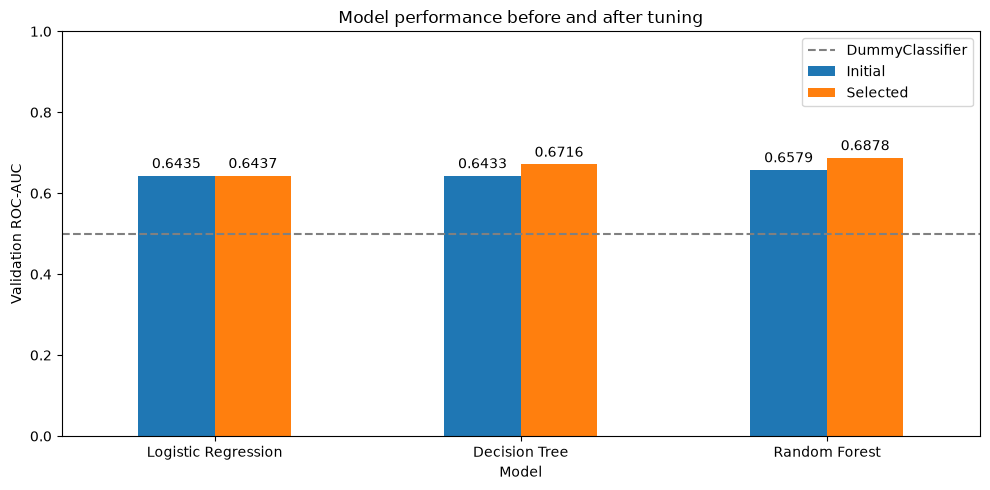

In [171]:
# Compare initial and selected ROC-AUC scores
tuning_summary = pd.DataFrame({
    "Initial": [
        model_results["Logistic Regression"]["ROC-AUC"],
        model_results["Decision Tree"]["ROC-AUC"],
        model_results["Random Forest (sqrt)"]["ROC-AUC"]
    ],

    "Selected": [
        model_results["Logistic Regression (tuned)"]["ROC-AUC"],
        model_results["Decision Tree (tuned)"]["ROC-AUC"],
        model_results["Random Forest (tuned)"]["ROC-AUC"]
    ]

}, index=[
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
])

ax = tuning_summary.plot(
    kind="bar",
    figsize=(10, 5)
)

# Add the baseline as a reference
plt.axhline(
    model_results["DummyClassifier"]["ROC-AUC"],
    color="gray",
    linestyle="--",
    label="DummyClassifier"
)

# Display values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.title("Model performance before and after tuning")
plt.ylabel("Validation ROC-AUC")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Model,,,,,,,,
DummyClassifier,0.8021,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000,0.0000
Logistic Regression (tuned),0.6035,0.2735,0.6057,0.3768,0.6437,0.0007,0.6452,0.0015
Decision Tree (tuned),0.8030,0.5236,0.0545,0.0987,0.6716,0.0013,0.6927,0.0211
Random Forest (tuned),0.8043,0.5587,0.0538,0.0982,0.6878,0.0013,0.7209,0.0332


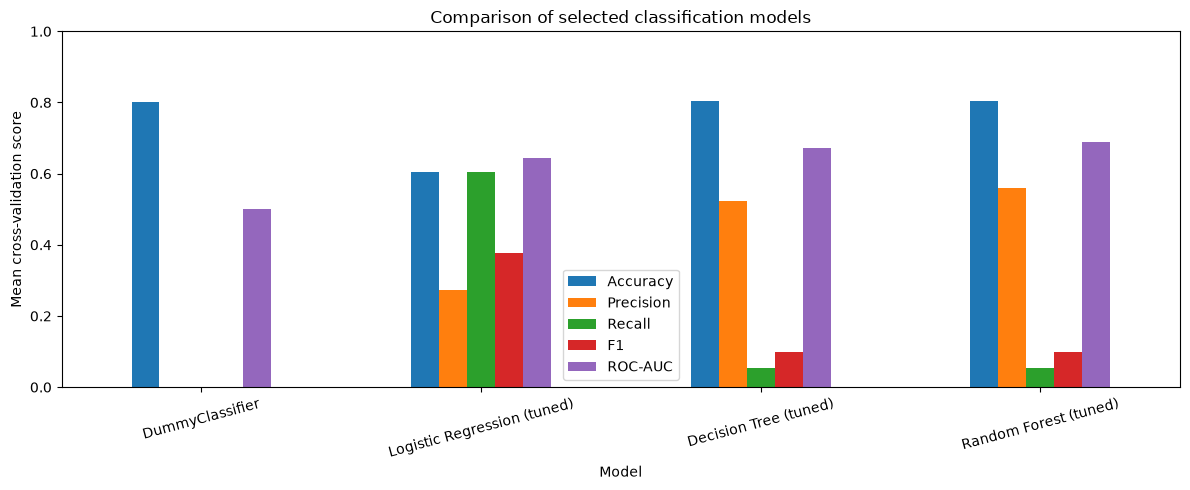

In [172]:
# Compare the selected configurations
best_models_comparison = compare_models([
    "DummyClassifier",
    "Logistic Regression (tuned)",
    "Decision Tree (tuned)",
    "Random Forest (tuned)"
])

best_models_comparison[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Comparison of selected classification models")
plt.ylabel("Mean cross-validation score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Define the selected Random Forest configuration
# Based on the hyperparameter tuning in Section 7.7.3.2

final_model = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=50,
        max_features=None,
        class_weight=None,
        criterion="gini",
        bootstrap=True,
        random_state=42,
        n_jobs=2
    ))
])

print("Selected model: Random Forest")
print("\nSelected hyperparameters:")

display(final_model["classifier"].get_params())

Selected model: Random Forest

Selected hyperparameters:


{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 15,
 'max_features': None,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 50,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': 2,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

**Findings – 7.8:**

- All investigated machine learning model types outperform the DummyClassifier baseline in terms of ROC-AUC.
- Hyperparameter tuning provides limited improvement for Logistic Regression but improves the predictive performance of both tree-based models.
- The selected Decision Tree achieves a validation ROC-AUC of 0.6716, while the selected Random Forest achieves the highest validation ROC-AUC of 0.6878.
- Random Forest is therefore selected for final evaluation based on our primary model selection metric.
- The selected Random Forest exhibits moderate discriminative performance and a generalization gap of 0.0332.
- However, recall remains limited at the default classification threshold of 0.5.
- The best balanced Random Forest achieves a similar ROC-AUC of 0.6867 and substantially higher recall at the default threshold. This highlights the importance of distinguishing between discriminative performance and threshold-dependent classification performance.

The selected Random Forest configuration is retained for final evaluation. Before accessing the holdout test set, we investigate alternative classification thresholds using out-of-fold predictions from the training data.

## 8. Model Evaluation and Interpretation

In Section 7, we developed, compared and optimized three supervised machine learning model types. Random Forest was selected based on its superior validation ROC-AUC.

We now evaluate the selected model and investigate its practical applicability to the prediction of arrival delays.

**The plan:**

1. Classification threshold selection.
2. Final test evaluation.
3. Error analysis.
4. Feature importance and model interpretation.

The purpose is to assess both predictive performance and the potential operational value of the model.

The holdout test set is reserved for final evaluation after the model configuration and classification threshold have been selected.

### 8.1 Classification Threshold Selection

**What we do:** We investigate how different classification thresholds affect the performance of the selected Random Forest model.

**Why:** The selected model achieves the highest validation ROC-AUC but identifies relatively few delayed flights at the default classification threshold of 0.5.

A lower classification threshold may allow the model to identify more delayed flights, although this may also increase the number of false-positive predictions.

To avoid using the holdout test set for threshold selection, we generate out-of-fold predicted probabilities using the existing three-fold stratified cross-validation strategy.

Each training observation receives a prediction from a model that has not been trained on that observation.

We compare alternative thresholds using precision, recall, F1-score and the proportion of flights generating delay alerts.

Since the operational costs of false positives and false negatives are unknown, we use F1-score as an illustrative criterion for selecting a threshold rather than claiming that it represents the optimal business decision.

In [25]:
from sklearn.model_selection import cross_val_predict

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix
)

final_model.set_params(classifier__verbose=2)

# Generate out-of-fold predicted probabilities
oof_probabilities = cross_val_predict(
    final_model,
    X_train_raw,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1,
    verbose=10
)[:, 1]

print("Number of predictions:", len(oof_probabilities))

print("Out-of-fold ROC-AUC:",
      round(roc_auc_score(y_train, oof_probabilities), 4))

print("Minimum predicted probability:",
      round(oof_probabilities.min(), 4))

print("Maximum predicted probability:",
      round(oof_probabilities.max(), 4))

print("Mean predicted probability:",
      round(oof_probabilities.mean(), 4))

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 1 of 100building tree 2 of 100

building tree 3 of 100
building tree 4 of 100
building tree 5 of 100
building tree 6 of 100
building tree 7 of 100
building tree 8 of 100
building tree 9 of 100
building tree 10 of 100
building tree 11 of 100
building tree 12 of 100
building tree 13 of 100
building tree 14 of 100
building tree 15 of 100
building tree 16 of 100
building tree 17 of 100
building tree 18 of 100
building tree 19 of 100
building tree 20 of 100
building tree 21 of 100
building tree 22 of 100
building tree 23 of 100
building tree 24 of 100
building tree 25 of 100
building tree 26 of 100
building tree 27 of 100
building tree 28 of 100
building tree 29 of 100
building tree 30 of 100
building tree 31 of 100
building tree 32 of 100
building tree 33 of 100
building tree 34 of 100
building tree 35 of 100
building tree 36 of 100
building tree 37 of 100
building tree 38 of 100
building tree 39 of 100


[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:  1.7min


building tree 40 of 100
building tree 41 of 100
building tree 42 of 100
building tree 43 of 100
building tree 44 of 100
building tree 45 of 100
building tree 46 of 100
building tree 47 of 100
building tree 48 of 100
building tree 49 of 100
building tree 50 of 100
building tree 51 of 100
building tree 52 of 100
building tree 53 of 100
building tree 54 of 100
building tree 55 of 100
building tree 56 of 100
building tree 57 of 100
building tree 58 of 100
building tree 59 of 100
building tree 60 of 100
building tree 61 of 100
building tree 62 of 100
building tree 63 of 100
building tree 64 of 100
building tree 65 of 100
building tree 66 of 100
building tree 67 of 100
building tree 68 of 100
building tree 69 of 100
building tree 70 of 100
building tree 71 of 100
building tree 72 of 100
building tree 73 of 100
building tree 74 of 100
building tree 75 of 100
building tree 76 of 100
building tree 77 of 100
building tree 78 of 100
building tree 79 of 100
building tree 80 of 100
building tree 81

[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:  4.5min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    1.1s finished
[Parallel(n_jobs=1)]: Done   1 tasks      | elapsed:  4.5min
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 1 of 100building tree 2 of 100

building tree 3 of 100
building tree 4 of 100
building tree 5 of 100
building tree 6 of 100
building tree 7 of 100
building tree 8 of 100
building tree 9 of 100
building tree 10 of 100
building tree 11 of 100
building tree 12 of 100
building tree 13 of 100
building tree 14 of 100
building tree 15 of 100
building tree 16 of 100
building tree 17 of 100
building tree 18 of 100
building tree 19 of 100
building tree 20 of 100
building tree 21 of 100
building tree 22 of 100
building tree 23 of 100
building tree 24 of 100
building tree 25 of 100
building tree 26 of 100
building tree 27 of 100
building tree 28 of 100
building tree 29 of 100
building tree 30 of 100
building tree 31 of 100
building tree 32 of 100
building tree 33 of 100
building tree 34 of 100
building tree 35 of 100
building tree 36 of 100
building tree 37 of 100
building tree 38 of 100
building tree 39 of 100


... (5 outputs left out)

building tree 40 of 100
building tree 41 of 100
building tree 42 of 100
building tree 43 of 100
building tree 44 of 100
building tree 45 of 100
building tree 46 of 100
building tree 47 of 100
building tree 48 of 100
building tree 49 of 100
building tree 50 of 100
building tree 51 of 100
building tree 52 of 100
building tree 53 of 100
building tree 54 of 100
building tree 55 of 100
building tree 56 of 100
building tree 57 of 100
building tree 58 of 100
building tree 59 of 100
building tree 60 of 100
building tree 61 of 100
building tree 62 of 100
building tree 63 of 100
building tree 64 of 100
building tree 65 of 100
building tree 66 of 100
building tree 67 of 100
building tree 68 of 100
building tree 69 of 100
building tree 70 of 100
building tree 71 of 100
building tree 72 of 100
building tree 73 of 100
building tree 74 of 100
building tree 75 of 100
building tree 76 of 100
building tree 77 of 100
building tree 78 of 100
building tree 79 of 100
building tree 80 of 100
building tree 81

[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:  4.4min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:    0.4s


Number of predictions: 961805
Out-of-fold ROC-AUC: 0.6877
Minimum predicted probability: 0.008
Maximum predicted probability: 0.7753
Mean predicted probability: 0.1978


[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    1.1s finished
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed: 13.5min finished


In [26]:
# Save out-of-fold predictions for reproducibility
oof_results = pd.DataFrame({
    "Actual": y_train,
    "Predicted_probability": oof_probabilities
}, index=y_train.index)

oof_results.to_csv(
    "random_forest_oof_predictions.csv",
    index=True
)

display(oof_results.head())

,Actual,Predicted_probability
19904,0,0.241267
239705,0,0.169158
78905,0,0.240737
679270,0,0.192599
217620,0,0.108335


In [27]:
# Investigate alternative classification thresholds
threshold_results = []

thresholds = np.round(
    np.arange(0.05, 0.61, 0.01), 2
)
for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),

        "Accuracy": accuracy_score(
            y_train, predictions
        ),

        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_train, predictions
        ),

        "F1": f1_score(
            y_train, predictions
        ),

        "Alert rate": predictions.mean()
    })

threshold_comparison = pd.DataFrame(
    threshold_results
)

# Display selected thresholds
display(
    threshold_comparison[
        threshold_comparison["Threshold"].isin([
            0.05, 0.10, 0.15, 0.20, 0.25,
            0.30, 0.35, 0.40, 0.45, 0.50, 0.60
        ])
    ].round(4)
)

,Threshold,Accuracy,Precision,Recall,F1,Alert rate
0,0.05,0.2072,0.1995,0.9977,0.3325,0.9899
5,0.10,0.3330,0.2216,0.9433,0.3589,0.8425
10,0.15,0.5076,0.2592,0.8008,0.3916,0.6115
15,0.20,0.6391,0.3018,0.6267,0.4074,0.4111
20,0.25,0.7333,0.3577,0.4365,0.3932,0.2416
25,0.30,0.7743,0.4067,0.3053,0.3488,0.1486
30,0.35,0.7926,0.4496,0.2124,0.2885,0.0935
35,0.40,0.8013,0.4931,0.1404,0.2186,0.0564
40,0.45,0.8038,0.5265,0.0889,0.1522,0.0334
45,0.50,0.8043,0.5585,0.0538,0.0982,0.0191


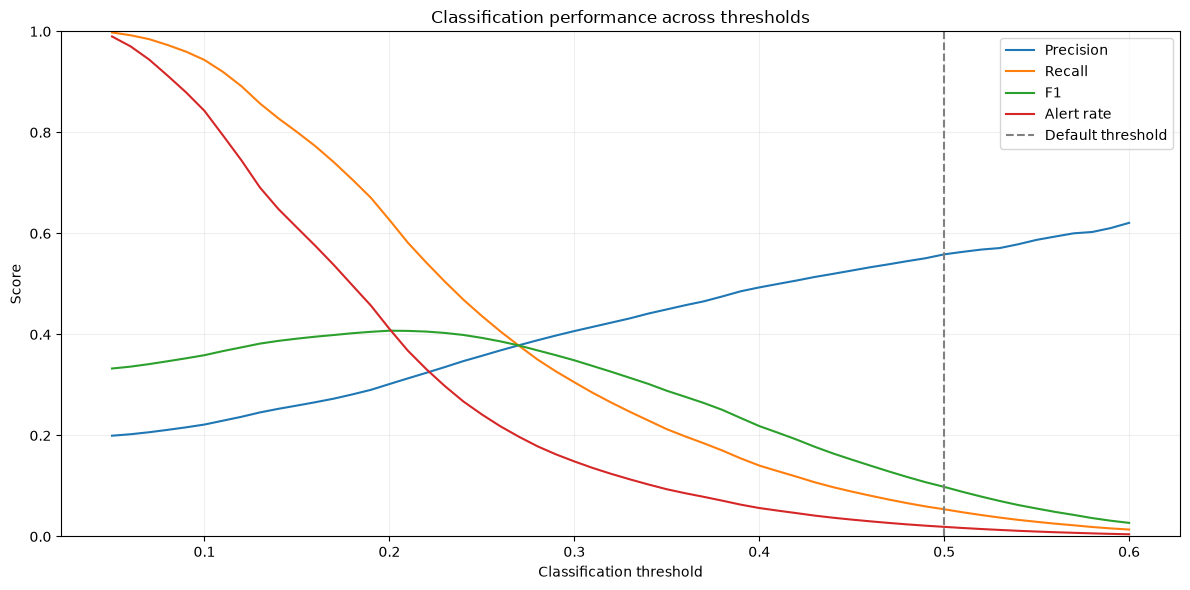

In [28]:
# Visualize the effect of classification thresholds
plt.figure(figsize=(12, 6))

for metric in ["Precision", "Recall", "F1", "Alert rate"]:

    plt.plot(
        threshold_comparison["Threshold"],
        threshold_comparison[metric],
        label=metric
    )

# Default classification threshold
plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Default threshold"
)

plt.title("Classification performance across thresholds")
plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [29]:
# Select the threshold with the highest F1-score
best_threshold_row = threshold_comparison.loc[
    threshold_comparison["F1"].idxmax()
]

selected_threshold = float(
    best_threshold_row["Threshold"]
)

# Retrieve default threshold performance
default_threshold_row = threshold_comparison.loc[
    threshold_comparison["Threshold"] == 0.5
].iloc[0]

# Compare the default and selected threshold
threshold_summary = pd.DataFrame(
    [
        default_threshold_row,
        best_threshold_row
    ],
    index=[
        "Default threshold",
        "Selected threshold"
    ]
)

display(threshold_summary.round(4))

print("Selected classification threshold:",
      selected_threshold)

,Threshold,Accuracy,Precision,Recall,F1,Alert rate
Default threshold,0.5,0.8043,0.5585,0.0538,0.0982,0.0191
Selected threshold,0.2,0.6391,0.3018,0.6267,0.4074,0.4111


Selected classification threshold: 0.2


**Findings – 8.1:**

- The selected Random Forest achieves an out-of-fold ROC-AUC of 0.6877, consistent with the validation ROC-AUC obtained during hyperparameter tuning.
- A classification threshold of 0.20 achieves the highest F1-score among the investigated thresholds.
- Reducing the threshold from 0.50 to 0.20 increases recall from 0.0538 to 0.6267, allowing the model to identify a substantially larger proportion of delayed flights.
- F1-score increases from 0.0982 to 0.4074, while precision decreases from 0.5585 to 0.3018.
- The alert rate increases from 1.91% to 41.11%, illustrating the operational trade-off between identifying potential delays and generating false-positive predictions.
- Changing the classification threshold affects classification performance but does not change the model's underlying discriminative ability.
- Since the operational costs of incorrect predictions are unknown, the selected threshold represents an illustrative balance between precision and recall rather than a demonstrated business optimum.

The classification threshold of 0.20 is retained for final evaluation on the holdout test set.

### 8.2 Final Test Evaluation

**What we do:** We train the selected Random Forest configuration on the complete training dataset and evaluate its predictive performance on the holdout test set.

**Why:** Following model development, hyperparameter tuning and classification threshold selection, we need to assess how well the selected model generalizes to unseen observations.

The final model is trained on all 961,805 training observations and evaluated on the 50,622 holdout test observations.

We compare the default classification threshold of 0.50 with the selected threshold of 0.20 to assess their impact on classification performance.

ROC-AUC, Average Precision, accuracy, precision, recall, F1-score and alert rate are reported.

No further model or threshold adjustments are made based on the test results.

In [30]:
# Train the selected model on the complete training dataset

final_model.fit(X_train_raw, y_train)

# Generate predicted probabilities on the holdout test set
test_probabilities = final_model.predict_proba(
    X_test_raw
)[:, 1]

# Generate predictions using both thresholds
test_predictions_default = (
    test_probabilities >= 0.5
).astype(int)

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print("Training observations:", len(y_train))
print("Test observations:", len(y_test))
print("Selected threshold:", selected_threshold)
print("Final model training completed.")

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 1 of 100building tree 2 of 100

building tree 3 of 100
building tree 4 of 100
building tree 5 of 100
building tree 6 of 100
building tree 7 of 100
building tree 8 of 100
building tree 9 of 100
building tree 10 of 100
building tree 11 of 100
building tree 12 of 100
building tree 13 of 100
building tree 14 of 100
building tree 15 of 100
building tree 16 of 100
building tree 17 of 100
building tree 18 of 100
building tree 19 of 100
building tree 20 of 100
building tree 21 of 100
building tree 22 of 100
building tree 23 of 100
building tree 24 of 100
building tree 25 of 100
building tree 26 of 100
building tree 27 of 100
building tree 28 of 100
building tree 29 of 100
building tree 30 of 100
building tree 31 of 100
building tree 32 of 100
building tree 33 of 100
building tree 34 of 100
building tree 35 of 100
building tree 36 of 100
building tree 37 of 100
building tree 38 of 100
building tree 39 of 100


[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:  3.3min


building tree 40 of 100
building tree 41 of 100
building tree 42 of 100
building tree 43 of 100
building tree 44 of 100
building tree 45 of 100
building tree 46 of 100
building tree 47 of 100
building tree 48 of 100
building tree 49 of 100
building tree 50 of 100
building tree 51 of 100
building tree 52 of 100
building tree 53 of 100
building tree 54 of 100
building tree 55 of 100
building tree 56 of 100
building tree 57 of 100
building tree 58 of 100
building tree 59 of 100
building tree 60 of 100
building tree 61 of 100
building tree 62 of 100
building tree 63 of 100
building tree 64 of 100
building tree 65 of 100
building tree 66 of 100
building tree 67 of 100
building tree 68 of 100
building tree 69 of 100
building tree 70 of 100
building tree 71 of 100
building tree 72 of 100
building tree 73 of 100
building tree 74 of 100
building tree 75 of 100
building tree 76 of 100
building tree 77 of 100
building tree 78 of 100
building tree 79 of 100
building tree 80 of 100
building tree 81

[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:  9.0min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:    0.1s


Training observations: 961805
Test observations: 50622
Selected threshold: 0.2
Final model training completed.


[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.2s finished


In [31]:
from sklearn.metrics import average_precision_score

# Evaluate classification performance
def evaluate_test_predictions(predictions, threshold):

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions
        ),
        "F1": f1_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(
            y_test, test_probabilities
        ),
        "Average Precision": average_precision_score(
            y_test, test_probabilities
        ),
        "Alert rate": predictions.mean()
    }


test_results = pd.DataFrame({

    "Default threshold": evaluate_test_predictions(
        test_predictions_default, 0.5
    ),

    "Selected threshold": evaluate_test_predictions(
        test_predictions, selected_threshold
    )

}).T

display(test_results.round(4))

# Compare validation and test discrimination
print("Cross-validation ROC-AUC: 0.6878")

print(
    "Holdout test ROC-AUC:",
    round(roc_auc_score(y_test, test_probabilities), 4)
)

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Alert rate
Default threshold,0.5,0.8044,0.5581,0.0556,0.1011,0.6948,0.3649,0.0197
Selected threshold,0.2,0.6403,0.3047,0.6374,0.4123,0.6948,0.3649,0.4141


Cross-validation ROC-AUC: 0.6878
Holdout test ROC-AUC: 0.6948


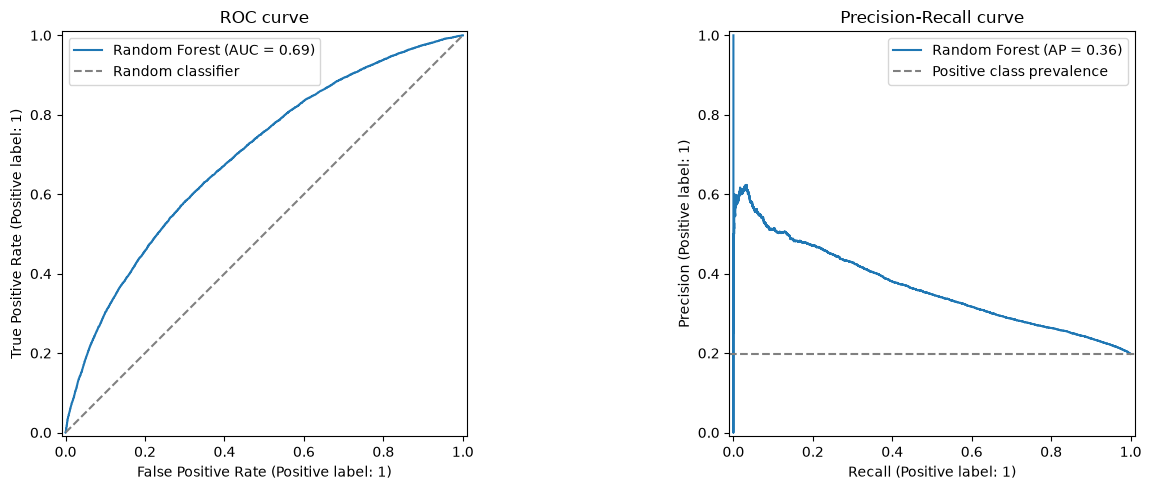

In [32]:
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Random Forest",
    ax=axes[0]
)

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

axes[0].set_title("ROC curve")
axes[0].legend()


# Precision-Recall curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Random Forest",
    ax=axes[1]
)

axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label="Positive class prevalence"
)

axes[1].set_title("Precision-Recall curve")
axes[1].legend()

plt.tight_layout()
plt.show()

In [33]:
# Save holdout test predictions

test_prediction_results = pd.DataFrame({

    "Actual": y_test,
    "Predicted_probability": test_probabilities,
    "Prediction_default": test_predictions_default,
    "Prediction_selected": test_predictions

}, index=y_test.index)

test_prediction_results.to_csv(
    "random_forest_test_predictions.csv",
    index=True
)

test_results.to_csv(
    "random_forest_test_results.csv"
)

display(test_prediction_results.head())

,Actual,Predicted_probability,Prediction_default,Prediction_selected
325415,1,0.521927,1,1
623456,0,0.185907,0,0
44118,0,0.143607,0,0
34510,0,0.119000,0,0
522087,0,0.208017,0,1


**Findings – 8.2:**

- The final Random Forest achieves a holdout test ROC-AUC of 0.6948, compared with a mean validation ROC-AUC of 0.6878.
- The consistency between validation and test performance suggests that the selected model generalizes well to unseen observations within the sampled period.
- At the selected classification threshold of 0.20, the model achieves a recall of 0.6374, precision of 0.3047 and F1-score of 0.4123.
- Compared with the default threshold of 0.50, the selected threshold identifies substantially more delayed flights at the expense of lower precision and accuracy.
- The model achieves an Average Precision of 0.3649, exceeding the positive class prevalence of approximately 0.198.
- Approximately 41.4% of flights generate delay alerts at the selected threshold, highlighting the potential operational workload associated with increased recall.
- Although the model demonstrates predictive value, its moderate discriminative performance and relatively low precision require careful consideration before operational deployment.

No further model or threshold adjustments are made based on the holdout test results.

### 8.3 Error Analysis

**What we do:** We investigate the classification errors made by the final Random Forest model using confusion matrices at the default and selected classification thresholds.

**Why:** Although the evaluation metrics provide an overall assessment of predictive performance, they do not directly illustrate the number and types of classification errors.

In the context of Delta Air Lines:

- True positives represent correctly identified arrival delays.
- True negatives represent correctly identified non-delayed flights.
- False positives represent unnecessary delay alerts.
- False negatives represent arrival delays that the model fails to identify.

Comparing these outcomes allows us to assess the potential operational consequences of the selected classification threshold.

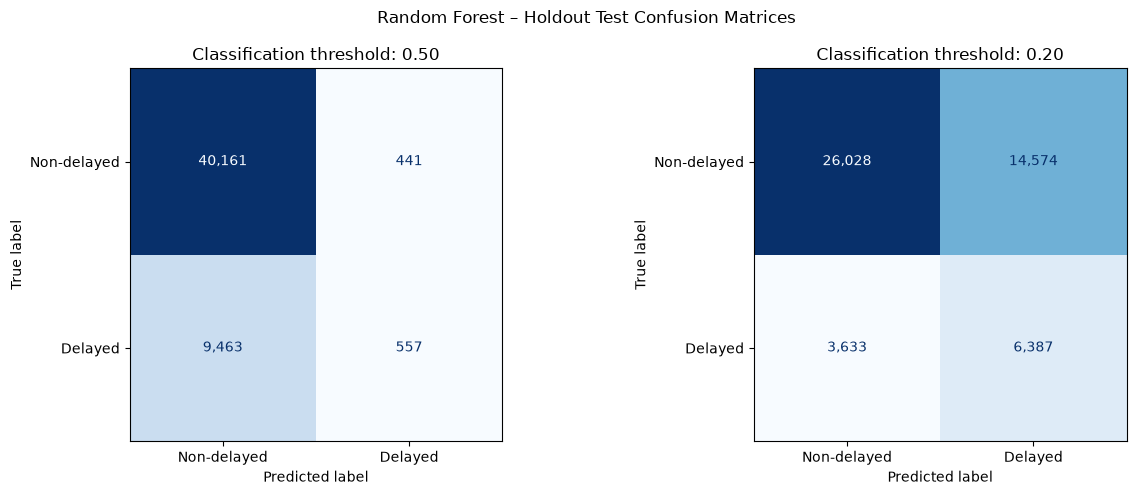

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

# Compare confusion matrices across thresholds
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, predictions, threshold in [
    (axes[0], test_predictions_default, 0.5),
    (axes[1], test_predictions, selected_threshold)
]:

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Non-delayed", "Delayed"],
        cmap="Blues",
        values_format=",d",
        colorbar=False,
        ax=ax
    )

    ax.set_title(
        f"Classification threshold: {threshold:.2f}"
    )

plt.suptitle("Random Forest – Holdout Test Confusion Matrices")
plt.tight_layout()
plt.show()

In [35]:
# Summarize classification errors and operational implications

def summarize_errors(predictions):

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    return {
        "True positives": tp,
        "True negatives": tn,
        "False positives": fp,
        "False negatives": fn,
        "Total alerts": tp + fp,
        "Missed delays (%)": fn / (fn + tp) * 100,
        "False alerts (%)": fp / (fp + tp) * 100,
        "Alerts per 1,000 flights": (
            (tp + fp) / len(y_test) * 1000
        )
    }


error_comparison = pd.DataFrame({

    "Default threshold": summarize_errors(
        test_predictions_default
    ),

    "Selected threshold": summarize_errors(
        test_predictions
    )

}).T

display(error_comparison.round(2))

,True positives,True negatives,False positives,False negatives,Total alerts,Missed delays (%),False alerts (%),"Alerts per 1,000 flights"
Default threshold,557.0,40161.0,441.0,9463.0,998.0,94.44,44.19,19.71
Selected threshold,6387.0,26028.0,14574.0,3633.0,20961.0,36.26,69.53,414.07


### 8.4 Feature Importance and Model Interpretation

**What we do:** We apply permutation importance to investigate which pre-departure flight characteristics contribute most to the predictive performance of the final Random Forest model.

**Why:** Our machine learning question concerns both predictive performance and the relative importance of the available flight characteristics.

Permutation importance measures how predictive performance changes when the values of an individual predictor are randomly shuffled, disrupting its relationship with the remaining data.

We use ROC-AUC as the scoring metric to assess feature importance independently of the selected classification threshold.

The analysis is conducted on the original eight predictors using the fitted preprocessing and classification pipeline. This allows categorical predictors such as ORIGIN and DEST to be evaluated collectively rather than as individual one-hot encoded features.

Each predictor is permuted five times to assess the variability of the estimated importance.

The results describe the predictive importance of features within the selected model and should not be interpreted as evidence of causal relationships. Correlations between predictors may also influence their estimated importance.

In [36]:
from sklearn.inspection import permutation_importance

# Disable detailed Random Forest prediction logs
final_model.set_params(classifier__verbose=0)

# Calculate permutation importance on the holdout test set
permutation_results = permutation_importance(
    final_model,
    X_test_raw,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# Summarize feature importance
importance_df = pd.DataFrame({
    "Feature": X_test_raw.columns,
    "Mean importance": permutation_results.importances_mean,
    "Importance SD": permutation_results.importances_std
})

importance_df = importance_df.sort_values(
    "Mean importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

,Feature,Mean importance,Importance SD
0,DEP_MINUTES,0.0947,0.0020
1,MONTH,0.0686,0.0025
2,DAY_OF_WEEK,0.0321,0.0011
3,ORIGIN,0.0191,0.0004
4,DEST,0.0187,0.0004
5,ARR_MINUTES,0.0177,0.0006
6,DISTANCE,0.0054,0.0002
7,CRS_ELAPSED_TIME,0.0040,0.0002


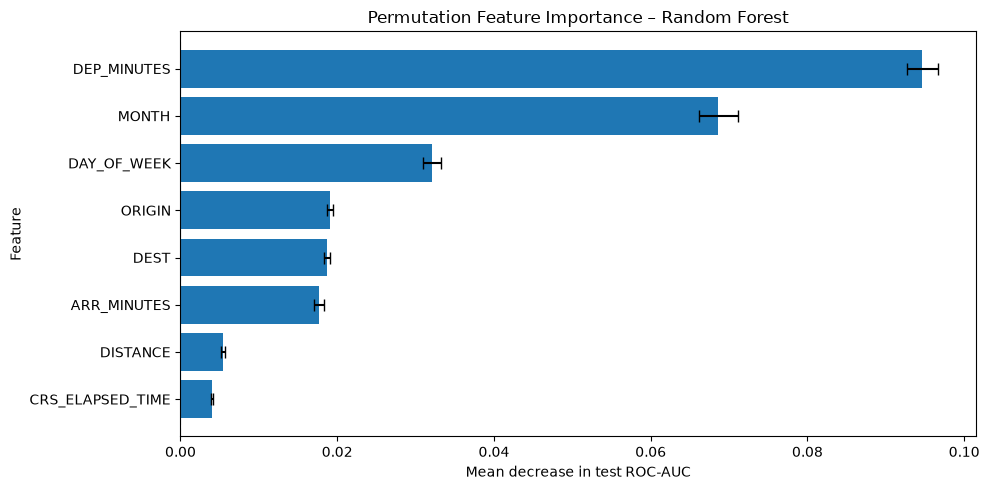

In [37]:
# Visualize permutation feature importance
importance_plot = importance_df.sort_values(
    "Mean importance",
    ascending=True
)

plt.figure(figsize=(10, 5))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Mean importance"],
    xerr=importance_plot["Importance SD"],
    capsize=4
)

plt.axvline(
    0,
    color="gray",
    linestyle="--"
)

plt.title("Permutation Feature Importance – Random Forest")
plt.xlabel("Mean decrease in test ROC-AUC")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [38]:
# Save feature importance results

importance_df.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

print("Feature importance results saved.")

Feature importance results saved.
